# **Training ML models for predicting turbidity in the DWTP inlet**

## **Give google drive access**

In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
%cd "/content/drive/My Drive/Colab Notebooks/Turbidity model - Hang_s thesis/ML_turbidity_prediction-main"

Mounted at /content/drive
/content/drive/My Drive/Colab Notebooks/Turbidity model - Hang_s thesis/ML_turbidity_prediction-main


In [ ]:
!pip install scikit-learn-intelex

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.0/32.0 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 61.8 MB/s eta 0:00:00
  Attempting uninstall: tbb
    Found existing installation: tbb 2022.3.1
    Uninstalling tbb-2022.3.1:
      Successfully uninstalled tbb-2022.3.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mkl 2025.3.1 requires tbb==2022.*, but you have tbb 2023.1.0 which is incompatible.


## **TRAINING XGB, RF, LSTM and ARIMA using randmon split**

### Model to run in this script

In [ ]:
"""
Turbidity forecasting -- persistence, RF, XGBoost, LSTM and ARIMA under ONE
non-chronological protocol, in two split flavours.

Every model is trained on the same rows, split the same way, scaled by the same
fitted scalers, and scored on the SAME test rows in FTU against the SAME
persistence baseline.

SPLIT MODES  (SPLIT_MODE)
-------------------------
"random"  -- plain shuffled 80/20 over the individual windows.
"block"   -- the series is cut into contiguous blocks of BLOCK_DAYS days and
             whole blocks are assigned to train or test at random. Windows that
             straddle a boundary are purged, so train and test share no raw
             hour. Tuning uses GroupKFold with the block as the group.

THE INPUT WINDOW, AND WHY THE TREES CAN SEE LESS OF IT
------------------------------------------------------
A contiguous INPUT_WINDOW-hour window is always built first. It is the master:
it decides which rows survive the NaN and mask filters, and therefore which
rows every model is trained and scored on.

TREE_LAG_OFFSETS then selects a SUBSET OF ITS COLUMNS for RF and XGBoost -- for
example [1, 2, 3, 23, 24] keeps only the three freshest hours plus the diurnal
echo, motivated by the SHAP lag profiles. The LSTM always receives the full
contiguous window, because a recurrent network assumes equally spaced steps and
sparse lags would violate that.

Doing it by column selection rather than by building a second window set means
the two model families are trained on identical rows with identical scalers.
The only thing that differs is which columns each sees, which is exactly the
comparison intended.

HOW EACH MODEL SEES THE SPLIT
-----------------------------
RF / XGB   the flattened window, restricted to TREE_LAG_OFFSETS
LSTM       the same matrix reshaped to (n, INPUT_WINDOW, n_features)

ARIMA  -- the one that needs care
    SARIMAX is sequential; it cannot be handed scattered windows. Two stages,
    deliberately separated:

    (1) PARAMETER ESTIMATION sees training rows only. The endogenous series is
        set to NaN at every test target hour (and at every gap-filled hour).
        The Kalman filter handles missing observations natively, so no test
        value can influence the estimated coefficients. Order selection (d by
        ADF/KPSS, then p,q by AIC) runs on that same NaN-holed series.

    (2) PREDICTION applies those FIXED coefficients to the fully observed
        series via results.apply(), and reads off the h-step-ahead forecast at
        each test target hour -- i.e. conditioned on observations up to t-h.

    Stage (2) is what makes the comparison fair rather than generous. The tree
    and LSTM models receive sensor_turbidity at t-1 as an input feature even
    when t-1 is itself a test target hour, because in operation that
    measurement exists. ARIMA is given exactly the same information and no
    more. Denying it stage (2) would have ARIMA forecasting 30 days blind
    inside each block while the trees read last hour off the sensor -- a
    comparison of protocols, not of models.

    Exogenous regressors are the same drivers the other models get, lagged by
    the forecast horizon, plus Fourier terms for the daily and annual cycles
    (which are known in advance and therefore not lagged).

OTHER CHOICES WORTH KNOWING
---------------------------
* LOG_TARGET (default True). Turbidity is heavily right-skewed: with a median
  near 15 FTU and a maximum near 167, MinMax scaling on the raw scale puts 95%
  of the data in the bottom ~15% of the range and squared-error loss is
  dominated by a handful of peaks. Modelling log1p(FTU) fixes the conditioning
  and matches what ARIMA needs anyway. Predictions are inverted before scoring.
* Persistence is computed from the raw target series, NOT from the feature
  matrix, so it exists even when turbidity is not among the inputs.
* The LSTM training loader is SHUFFLED. Windows are independent samples here;
  the sequence lives inside each window, not across them.
* A distribution report is printed for the realised split, including the R2
  floor of a constant train-mean predictor. On a random split that floor is ~0
  by construction; on a block split it should also be small. If it is not, the
  split is unbalanced and R2 is not a safe headline metric.

CHANGE ONE THING AT A TIME
--------------------------
When testing the sparse-lag design, keep all seven features. Reducing the lags
and the features in the same run makes the result unattributable.

Run:  python turbidity_models_splits.py
      python turbidity_models_splits.py --split block --block-days 30
"""

import argparse
import json
import os
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import (GroupKFold, KFold, RandomizedSearchCV,
                                     train_test_split)
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBRegressor

from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", ValueWarning)
warnings.simplefilter("ignore", UserWarning)


# =============================================================================
# CONFIG
# =============================================================================
DATA_CSV = "notebooks/FM_LSTM.csv"
MASK_NPY = "notebooks/turbidity_mask.npy"

SPLIT_MODE = "random"             # "random" | "block"
BLOCK_DAYS = 30

FEATURE_COLUMNS = [
    "sensor_turbidity",
    "Hag_dis",
    "sensor_temperature",
    "Nieu_EC",
    "Lob_turbidity",
    "flow_direction",
    "month",
]
TARGET = "sensor_turbidity"

INPUT_WINDOW = 24                 # contiguous master window, in hours
TREE_LAG_OFFSETS = [1, 2, 3, 20, 21, 22, 23, 24]   # RF/XGB only. None -> full window.
                                       # Hours before the forecast origin t;
                                       # each must be within 1..INPUT_WINDOW.

HORIZONS = [1,2,3,4,5,6]
TEST_FRACTION = 0.20

LOG_TARGET = True                 # model log1p(FTU); invert with expm1 before scoring
END_DATE = None                   # e.g. "2024-02-26" to truncate; None = all rows

K_FOLDS = 5
RANDOM_STATE = 42
SPLIT_SEED = 42
N_JOBS = -1

RUN_MODELS = ["rf","xgb"]        # add "rf","xgb", "lstm", "arima" as needed

MASK_TRUE_MEANS_INVALID = True
ENFORCE_MASK = True

# --- trees -------------------------------------------------------------------
TREE_N_ITER = 20
SEARCH_SUBSAMPLE = 3
XGB_DEVICE = "cuda"               # "cpu" if no GPU

RF_GRID = {
    "n_estimators": [50, 100, 200, 400],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt"],
    "max_samples": [0.5],
}
XGB_GRID = {
    "n_estimators": [200, 400, 800],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.5, 0.8, 1.0],
    "min_child_weight": [1, 5],
    "max_bin": [128],
}

# --- LSTM --------------------------------------------------------------------
LSTM_N_CANDIDATES = 10
LSTM_EPOCHS = 100
LSTM_PATIENCE = 5
LSTM_MIN_EPOCHS = 10
LSTM_BATCH_SIZE = 64
LSTM_VAL_FRACTION = 0.15
LSTM_SEARCH_SUBSAMPLE = 1
LSTM_SEARCH_SPACE = {
    "hidden_size": [32, 64, 128, 167, 216],
    "num_layers": [1, 2],
    "dropout": [0.0, 0.1, 0.2],
    "lr": [1e-5, 5e-5, 1e-4, 5e-4],
}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- ARIMA -------------------------------------------------------------------
ARIMA_FOURIER_DAILY = 3
ARIMA_FOURIER_ANNUAL = 2
ARIMA_P_GRID = [1, 2, 3]
ARIMA_Q_GRID = [0, 1, 2]
ARIMA_FORCE_ORDER = None
ARIMA_ADF_TAIL = 20000


def split_tag():
    if SPLIT_MODE == "random":
        return "random80"
    if SPLIT_MODE == "block":
        return f"block{BLOCK_DAYS}d80"
    raise ValueError(f"unknown SPLIT_MODE {SPLIT_MODE!r}")


def save_root():
    return f"trained_models_{split_tag()}"


def tree_tag():
    """Short label for the tree lag set, used in file and folder names."""
    return f"w{INPUT_WINDOW}" if not TREE_LAG_OFFSETS else \
           "L" + "-".join(str(k) for k in sorted({int(v) for v in TREE_LAG_OFFSETS}))


def tree_column_index(feature_columns, input_window=INPUT_WINDOW):
    """Columns of the flattened window that RF/XGB should see.

    The flat order is offset INPUT_WINDOW, …, 2, 1, each block holding all
    features, so the block for offset k begins at (input_window - k) * n_feat.
    """
    n_feat = len(feature_columns)
    if not TREE_LAG_OFFSETS:
        return np.arange(input_window * n_feat, dtype=int)
    idx = []
    for k in sorted({int(v) for v in TREE_LAG_OFFSETS}, reverse=True):
        b = input_window - k
        if not 0 <= b < input_window:
            raise ValueError(f"lag t-{k} lies outside the {input_window}-hour window")
        idx.extend(range(b * n_feat, (b + 1) * n_feat))
    return np.asarray(idx, dtype=int)


# =============================================================================
# 1. DATA
# =============================================================================
def load_data(data_csv=DATA_CSV, mask_npy=MASK_NPY):
    df = pd.read_csv(data_csv, index_col=0)
    df.index = pd.to_datetime(df.index)

    df["Lob_turbidity"] = pd.to_numeric(df["Lob_turbidity"], errors="coerce")
    df["Lob_turbidity"] = df["Lob_turbidity"].interpolate(method="linear").bfill()

    if "month" in df.columns:
        df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
        df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

    mask = np.load(mask_npy)
    if len(mask) != len(df):
        raise ValueError(f"mask length {len(mask)} != data length {len(df)}")
    valid = ~mask if MASK_TRUE_MEANS_INVALID else mask.astype(bool)

    if END_DATE is not None:
        keep = df.index < pd.Timestamp(END_DATE)
        n_drop = int((~keep).sum())
        if n_drop:
            print(f"  truncating at {END_DATE}: dropping {n_drop:,} trailing rows")
        df, valid = df.loc[keep], valid[keep]

    steps = df.index.to_series().diff().dropna().value_counts()
    if len(steps) > 1:
        print(f"  warning: index is not uniformly spaced -- {len(steps)} distinct "
              f"step sizes, most common {steps.index[0]}. ARIMA assumes a regular "
              f"grid; gaps are treated as consecutive observations.")

    print(f"Loaded {len(df):,} rows  ({df.index.min()} -> {df.index.max()})")
    print(f"  valid: {valid.sum():,}   invalid/gap-filled: {(~valid).sum():,}")
    return df, valid


def make_windows(df, valid, feature_columns, target=TARGET,
                 input_window=INPUT_WINDOW, forecast_horizon=1,
                 enforce_mask=ENFORCE_MASK):
    """Contiguous master window.

    X[k] = features over rows [i-input_window, i), flattened oldest-first;
    y[k] = target at row i + forecast_horizon - 1;
    persist[k] = last observed target, targ[i-1], exactly h steps before the
                 target and available whether or not turbidity is a feature.
    """
    h_off = forecast_horizon - 1
    feats = df[feature_columns].to_numpy(dtype=np.float32)
    targ = df[target].to_numpy(dtype=np.float32)
    valid = np.asarray(valid, dtype=bool)
    idx = df.index

    X, y, stamps, spans, persist = [], [], [], [], []
    for i in range(input_window, len(df) - h_off):
        win = feats[i - input_window:i]
        y_val = targ[i + h_off]
        p_val = targ[i - 1]
        if np.isnan(win).any() or np.isnan(y_val) or np.isnan(p_val):
            continue
        if enforce_mask and not (valid[i - input_window:i].all()
                                 and valid[i + h_off]):
            continue
        X.append(win.ravel())
        y.append(y_val)
        stamps.append(idx[i + h_off])
        spans.append((i - input_window, i + h_off))
        persist.append(p_val)

    return (np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32),
            pd.DatetimeIndex(stamps),
            np.asarray(spans, dtype=np.int64).reshape(-1, 2),
            np.asarray(persist, dtype=np.float32))


def expanded_feature_names(feature_columns, input_window=INPUT_WINDOW):
    """Names matching ravel() order: the t-24 block first, then t-23 … t-1."""
    return [f"{f} (t-{k})" for k in range(input_window, 0, -1)
            for f in feature_columns]


# --- split modes -------------------------------------------------------------
def random_split_indices(n, test_fraction=TEST_FRACTION, seed=SPLIT_SEED):
    idx_tr, idx_te = train_test_split(np.arange(n), test_size=test_fraction,
                                      shuffle=True, random_state=seed)
    return np.sort(idx_tr), np.sort(idx_te), None


def row_block_ids(index, block_days=BLOCK_DAYS):
    origin = index.min().normalize()
    hours = ((index - origin) / pd.Timedelta("1h")).to_numpy()
    return np.floor(hours / (block_days * 24.0)).astype(np.int64)


def block_split_indices(spans, row_block, test_fraction=TEST_FRACTION,
                        seed=SPLIT_SEED):
    rng = np.random.default_rng(seed)
    win_block = row_block[spans[:, 1]]
    blocks = np.unique(row_block)
    order = rng.permutation(blocks)
    s, e = spans[:, 0], spans[:, 1]
    span_len = e - s + 1

    def purity(chosen):
        row_is_test = np.isin(row_block, np.asarray(chosen, dtype=np.int64))
        cum = np.concatenate([[0], np.cumsum(row_is_test.astype(np.int64))])
        n_test_rows = cum[e + 1] - cum[s]
        return n_test_rows == 0, n_test_rows == span_len

    chosen = []
    pure_train = np.ones(len(spans), dtype=bool)
    pure_test = np.zeros(len(spans), dtype=bool)
    for b in order:
        kept = pure_train.sum() + pure_test.sum()
        if kept and pure_test.sum() / kept >= test_fraction:
            break
        trial = chosen + [int(b)]
        pt, pe = purity(trial)
        chosen, pure_train, pure_test = trial, pt, pe

    n_purged = int(len(spans) - pure_train.sum() - pure_test.sum())
    share = pure_test.sum() / max(pure_train.sum() + pure_test.sum(), 1)
    print(f"  {len(blocks):,} blocks of {BLOCK_DAYS} day(s); "
          f"{len(chosen):,} assigned to test")
    print(f"  purged {n_purged:,} boundary-crossing windows "
          f"({100 * n_purged / max(len(spans), 1):.2f}%) -- "
          f"train and test share no raw hour")
    if abs(share - test_fraction) > 0.03:
        print(f"  WARNING: realised test share {share:.1%} vs requested "
              f"{test_fraction:.0%}; adjust BLOCK_DAYS")
    return np.where(pure_train)[0], np.where(pure_test)[0], win_block


def split_windows(X, y, stamps, spans, row_block):
    if SPLIT_MODE == "random":
        idx_tr, idx_te, win_block = random_split_indices(len(X))
        print(f"\nRANDOM split (seed {SPLIT_SEED})")
    elif SPLIT_MODE == "block":
        print(f"\nBLOCK split ({BLOCK_DAYS}-day blocks, seed {SPLIT_SEED})")
        idx_tr, idx_te, win_block = block_split_indices(spans, row_block)
    else:
        raise ValueError(f"unknown SPLIT_MODE {SPLIT_MODE!r}")

    print(f"  train: {len(idx_tr):,} windows   "
          f"({stamps[idx_tr].min()} -> {stamps[idx_tr].max()})")
    print(f"  test : {len(idx_te):,} windows   "
          f"({stamps[idx_te].min()} -> {stamps[idx_te].max()})   "
          f"= {100 * len(idx_te) / (len(idx_tr) + len(idx_te)):.1f}%")

    if SPLIT_MODE == "random":
        print("  NOTE: test windows are interleaved with training windows. Every "
              "test window has temporal neighbours in training with near-identical "
              "inputs and targets. Read this as reconstruction, not forecasting.")
    else:
        print("  NOTE: no raw hour is shared, but test blocks are scattered through "
              "the record rather than following it. Seasonal climatology remains "
              "fully learnable. Still not a forward forecast.")

    groups_tr = None if win_block is None else win_block[idx_tr]
    return idx_tr, idx_te, groups_tr


# --- target transform & scaling ----------------------------------------------
def fwd_target(y):
    return np.log1p(np.asarray(y, dtype=np.float64)) if LOG_TARGET \
        else np.asarray(y, dtype=np.float64)


def inv_target(y):
    return np.expm1(np.asarray(y, dtype=np.float64)) if LOG_TARGET \
        else np.asarray(y, dtype=np.float64)


def fit_window_scalers(X_tr, y_tr, feature_columns, input_window=INPUT_WINDOW):
    """MinMaxScaler per feature, fit on TRAINING WINDOWS only.

    The target column is log1p-transformed first when LOG_TARGET, so the window
    copy of turbidity, the target and the persistence baseline share one scale.
    """
    n_feat = len(feature_columns)
    cube = X_tr.reshape(-1, input_window, n_feat)

    scaler_dict = {}
    for j, col in enumerate(feature_columns):
        vals = cube[:, :, j].reshape(-1, 1).astype(np.float64)
        if col == TARGET:
            vals = fwd_target(vals)
            vals = np.vstack([vals, fwd_target(y_tr).reshape(-1, 1)])
        sc = MinMaxScaler()
        sc.fit(vals)
        scaler_dict[col] = sc

    if TARGET not in feature_columns:
        sc = MinMaxScaler()
        sc.fit(fwd_target(y_tr).reshape(-1, 1))
        scaler_dict[TARGET] = sc

    for col, sc in scaler_dict.items():
        print(f"  scaler[{col}]: min={sc.data_min_[0]:.4f}  max={sc.data_max_[0]:.4f}")
    return scaler_dict


def apply_window_scalers(X, y, scaler_dict, feature_columns,
                         input_window=INPUT_WINDOW):
    n_feat = len(feature_columns)
    cube = X.reshape(-1, input_window, n_feat).astype(np.float64).copy()
    for j, col in enumerate(feature_columns):
        flat = cube[:, :, j].reshape(-1, 1)
        if col == TARGET:
            flat = fwd_target(flat)
        cube[:, :, j] = scaler_dict[col].transform(flat).reshape(
            cube.shape[0], input_window)
    Xs = cube.reshape(X.shape[0], -1).astype(np.float32)
    ys = scaler_dict[TARGET].transform(
        fwd_target(y).reshape(-1, 1)).ravel().astype(np.float32)
    return Xs, ys


def to_ftu(y_scaled, scaler_dict):
    """Scaled model space -> FTU. Every metric in this script is computed here."""
    a = scaler_dict[TARGET].inverse_transform(
        np.asarray(y_scaled, dtype=np.float64).reshape(-1, 1)).ravel()
    return inv_target(a)


# =============================================================================
# 2. SPLIT DIAGNOSTICS
# =============================================================================
def split_report(y_tr_ftu, y_te_ftu, folds=None):
    def d(a):
        a = np.asarray(a, float)
        a = a[np.isfinite(a)]
        return dict(n=len(a), mean=a.mean(), std=a.std(ddof=1), min=a.min(),
                    p25=np.percentile(a, 25), median=np.median(a),
                    p75=np.percentile(a, 75), p95=np.percentile(a, 95),
                    max=a.max())

    rows, index = [], []
    if folds is not None:
        for i, (tr, va) in enumerate(folds, 1):
            rows.append(d(y_tr_ftu[tr])); index.append(f"fold{i}_train")
            rows.append(d(y_tr_ftu[va])); index.append(f"fold{i}_val")
    rows.append(d(y_tr_ftu)); index.append("TRAIN_all")
    rows.append(d(y_te_ftu)); index.append("TEST")

    out = pd.DataFrame(rows, index=index)
    tm = out.loc["TRAIN_all", "mean"]
    out["shift_sigma"] = (out["mean"] - tm) / out["std"]
    out["R2_floor"] = -(out["shift_sigma"] ** 2)
    lo, hi = out.loc["TRAIN_all", "min"], out.loc["TRAIN_all", "max"]
    out["frac_outside_train_range"] = np.nan
    out.loc["TEST", "frac_outside_train_range"] = float(
        np.mean((y_te_ftu < lo) | (y_te_ftu > hi)))

    print("\n" + "=" * 100)
    print("TARGET DISTRIBUTION (FTU)")
    print("=" * 100)
    print(out.round(3).to_string())
    te = out.loc["TEST"]
    print(f"\n  test mean is {te['shift_sigma']:+.2f} test-sigma from the training mean")
    print(f"  -> a constant train-mean forecast scores R2 = {te['R2_floor']:.3f} here")
    if abs(te["shift_sigma"]) > 0.3:
        print("  !! sizeable level shift for a non-chronological split -- check the "
              "split is balanced before quoting R2")
    return out


# =============================================================================
# 3. METRICS  (all in FTU, all models, same rows)
# =============================================================================
def compute_metrics(name, y_true, y_pred, y_persist=None):
    y_true = np.asarray(y_true, float)
    y_pred = np.asarray(y_pred, float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    yt, yp = y_true[ok], y_pred[ok]

    mse = float(np.mean((yt - yp) ** 2))
    row = {
        "model": name,
        "n": int(ok.sum()),
        "RMSE_FTU": float(np.sqrt(mse)),
        "MAE_FTU": float(np.mean(np.abs(yt - yp))),
        "R2": float(r2_score(yt, yp)),
        "bias_FTU": float(np.mean(yp - yt)),
        "PBIAS_pct": float(100.0 * np.sum(yp - yt) / np.sum(yt)),
        "corr": float(np.corrcoef(yt, yp)[0, 1])
                if yt.std() > 0 and yp.std() > 0 else np.nan,
    }
    r = row["corr"]
    alpha = float(yp.std(ddof=1) / yt.std(ddof=1)) if yt.std(ddof=1) > 0 else np.nan
    beta = float(yp.mean() / yt.mean()) if yt.mean() != 0 else np.nan
    row["KGE"] = float(1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)) \
        if np.all(np.isfinite([r, alpha, beta])) else np.nan
    row["KGE_alpha"] = alpha
    row["KGE_beta"] = beta

    if yt.size:
        thr = np.percentile(yt, 95)
        hi = yt >= thr
        row["peak95_MAE"] = float(np.mean(np.abs(yt[hi] - yp[hi]))) if hi.any() else np.nan
        row["peak95_bias"] = float(np.mean(yp[hi] - yt[hi])) if hi.any() else np.nan

    if y_persist is not None:
        pers = np.asarray(y_persist, float)[ok]
        mse_p = float(np.mean((yt - pers) ** 2))
        row["skill_vs_persistence"] = float(1 - mse / mse_p) if mse_p > 0 else np.nan
    return row


def print_metrics(row):
    print(f"    {row['model']:12s} RMSE={row['RMSE_FTU']:8.3f}  "
          f"MAE={row['MAE_FTU']:7.3f}  R2={row['R2']:7.4f}  "
          f"KGE={row.get('KGE', float('nan')):7.4f}  "
          f"r={row.get('corr', float('nan')):+.3f}  "
          f"skill={row.get('skill_vs_persistence', float('nan')):+7.4f}")


# =============================================================================
# 4. CV FOLDS  (shared by trees and LSTM -- row indices, column-agnostic)
# =============================================================================
def make_cv(groups):
    if groups is None:
        return KFold(n_splits=K_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    return GroupKFold(n_splits=K_FOLDS)


def build_folds(X, y, groups):
    cv = make_cv(groups)
    return list(cv.split(X, y, groups)), cv


def holdout_indices(n, groups, frac, seed=RANDOM_STATE):
    """Early-stopping hold-out: random rows in random mode, whole blocks in block mode."""
    rng = np.random.default_rng(seed)
    if groups is None:
        perm = rng.permutation(n)
        cut = int(round((1 - frac) * n))
        return np.sort(perm[:cut]), np.sort(perm[cut:])
    blocks = np.unique(groups)
    order = rng.permutation(blocks)
    chosen, held = [], np.zeros(n, dtype=bool)
    for b in order:
        if held.sum() / n >= frac:
            break
        chosen.append(b)
        held = np.isin(groups, np.asarray(chosen))
    return np.where(~held)[0], np.where(held)[0]


# =============================================================================
# 5. TREE MODELS
# =============================================================================
def search_tree_model(kind, X, y, groups, subsample=SEARCH_SUBSAMPLE,
                      n_iter=TREE_N_ITER):
    if kind == "rf":
        base = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS)
        grid = RF_GRID
    else:
        base = XGBRegressor(objective="reg:squarederror", tree_method="hist",
                            device=XGB_DEVICE, random_state=RANDOM_STATE,
                            n_jobs=N_JOBS)
        grid = XGB_GRID

    if subsample and subsample > 1:
        X_s, y_s = X[::subsample], y[::subsample]
        g_s = None if groups is None else groups[::subsample]
        print(f"  tuning on every {subsample}th window: {len(X_s):,} of {len(X):,}")
    else:
        X_s, y_s, g_s = X, y, groups

    cv = make_cv(g_s)
    print(f"  CV: {type(cv).__name__}(n_splits={K_FOLDS})"
          + ("" if g_s is None else f" grouped by {len(np.unique(g_s)):,} blocks"))

    search = RandomizedSearchCV(base, param_distributions=grid, n_iter=n_iter,
                                cv=cv, scoring="neg_root_mean_squared_error",
                                random_state=RANDOM_STATE, n_jobs=N_JOBS,
                                verbose=1, refit=False)
    t0 = time.time()
    search.fit(X_s, y_s, groups=g_s)
    print(f"  search done in {time.time() - t0:.0f}s")

    best = dict(search.best_params_)
    print(f"  BEST {kind.upper()} PARAMS: {best}")
    i = int(search.best_index_)
    fold_scores = [-search.cv_results_[f"split{k}_test_score"][i] for k in range(K_FOLDS)]
    print("    per-fold RMSE: "
          + ", ".join(f"f{k+1}={s:.5f}" for k, s in enumerate(fold_scores))
          + f"   (spread {max(fold_scores) - min(fold_scores):.5f})")

    print(f"  refitting on all {len(X):,} rows x {X.shape[1]} columns ...")
    t0 = time.time()
    if kind == "rf":
        model = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_JOBS,
                                      bootstrap=True, **best)
    else:
        model = XGBRegressor(objective="reg:squarederror", tree_method="hist",
                             device=XGB_DEVICE, random_state=RANDOM_STATE,
                             n_jobs=N_JOBS, **best)
    model.fit(X, y)
    print(f"  refit done in {time.time() - t0:.0f}s")
    return model, best, fold_scores


# =============================================================================
# 6. LSTM  (always the full contiguous window)
# =============================================================================
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers=1, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers,
                            batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out)
        return self.fc(out[:, -1, :])


def _loader(X3d, y, batch_size, shuffle):
    ds = TensorDataset(torch.from_numpy(X3d), torch.from_numpy(y).unsqueeze(1))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def train_lstm(X3d_tr, y_tr, X3d_va, y_va, cfg, n_features,
               epochs=LSTM_EPOCHS, patience=LSTM_PATIENCE,
               min_epochs=LSTM_MIN_EPOCHS, batch_size=LSTM_BATCH_SIZE,
               verbose=False):
    torch.manual_seed(RANDOM_STATE)
    model = LSTMModel(n_features, cfg["hidden_size"], cfg["num_layers"],
                      cfg["dropout"]).to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=cfg["lr"])
    # windows are independent samples here -- shuffling is correct and matters
    train_loader = _loader(X3d_tr, y_tr, batch_size, shuffle=True)
    val_loader = _loader(X3d_va, y_va, batch_size, shuffle=False)

    best_val, best_state, bad = float("inf"), None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()

        model.eval()
        sse, n = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb)
                sse += torch.sum((pred - yb) ** 2).item()
                n += xb.size(0)
        val_rmse = float(np.sqrt(sse / max(n, 1)))
        if not np.isfinite(val_rmse):
            break
        if val_rmse < best_val - 1e-9:
            best_val, bad = val_rmse, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        elif epoch >= min_epochs:
            bad += 1
            if bad >= patience:
                if verbose:
                    print(f"      early stop at epoch {epoch} "
                          f"(best val RMSE {best_val:.5f})")
                break
        if verbose and epoch % 5 == 0:
            print(f"      epoch {epoch:3d}  val RMSE {val_rmse:.5f} "
                  f"(best {best_val:.5f})")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_val


def lstm_predict(model, X3d, batch_size=512):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X3d), batch_size):
            xb = torch.from_numpy(X3d[i:i + batch_size]).to(DEVICE)
            out.append(model(xb).cpu().numpy().ravel())
    return np.concatenate(out) if out else np.empty(0, dtype=np.float32)


def sample_lstm_configs(n=LSTM_N_CANDIDATES, space=LSTM_SEARCH_SPACE,
                        seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    seen, configs, guard = set(), [], 0
    while len(configs) < n and guard < 500:
        guard += 1
        cfg = {k: v[int(rng.integers(len(v)))] for k, v in space.items()}
        key = tuple(sorted(cfg.items()))
        if key not in seen:
            seen.add(key)
            configs.append(cfg)
    return configs


def run_lstm(X_tr, y_tr, X_te, folds, groups_tr, n_features, input_window):
    X3d_tr = X_tr.reshape(-1, input_window, n_features)
    X3d_te = X_te.reshape(-1, input_window, n_features)
    configs = sample_lstm_configs()
    sub = max(1, LSTM_SEARCH_SUBSAMPLE)
    print(f"\n  LSTM random search: {len(configs)} configs x {len(folds)} folds "
          f"on {DEVICE}  (full {input_window}-hour window)")

    results = []
    for ci, cfg in enumerate(configs, 1):
        t0, scores = time.time(), []
        for tr, va in folds:
            tr_s = tr[::sub] if sub > 1 else tr
            _, v = train_lstm(X3d_tr[tr_s], y_tr[tr_s], X3d_tr[va], y_tr[va],
                              cfg, n_features)
            scores.append(v)
        mean_rmse = float(np.mean(scores))
        results.append({"config": cfg, "mean_val_rmse": mean_rmse,
                        "fold_val_rmse": scores})
        print(f"    [{ci}/{len(configs)}] {cfg}  mean val RMSE = {mean_rmse:.5f} "
              f"({time.time() - t0:.0f}s)")

    results.sort(key=lambda r: r["mean_val_rmse"])
    best = results[0]
    print(f"  BEST LSTM CONFIG: {best['config']}  "
          f"mean val RMSE {best['mean_val_rmse']:.5f}")

    fit_idx, val_idx = holdout_indices(len(X3d_tr), groups_tr, LSTM_VAL_FRACTION)
    print(f"  refit on {len(fit_idx):,} windows, early stopping on {len(val_idx):,}"
          + (" (whole blocks held out)" if groups_tr is not None else ""))
    model, refit_val = train_lstm(X3d_tr[fit_idx], y_tr[fit_idx],
                                  X3d_tr[val_idx], y_tr[val_idx],
                                  best["config"], n_features, verbose=True)
    return model, best, results, refit_val, lstm_predict(model, X3d_te)


# =============================================================================
# 7. ARIMA
# =============================================================================
def arima_build_exog(df, drivers, horizon):
    """Fourier terms (known in advance) + drivers lagged by `horizon`."""
    n = len(df)
    pos = np.arange(n)
    cols = {}
    for k in range(1, ARIMA_FOURIER_DAILY + 1):
        cols[f"sin_d{k}"] = np.sin(2 * np.pi * k * pos / 24.0)
        cols[f"cos_d{k}"] = np.cos(2 * np.pi * k * pos / 24.0)
    for k in range(1, ARIMA_FOURIER_ANNUAL + 1):
        cols[f"sin_a{k}"] = np.sin(2 * np.pi * k * pos / 8766.0)
        cols[f"cos_a{k}"] = np.cos(2 * np.pi * k * pos / 8766.0)

    for d in drivers:
        if d not in df.columns:
            print(f"    warning: driver {d!r} not in data -- skipped")
            continue
        s = pd.to_numeric(df[d], errors="coerce").replace([np.inf, -np.inf], np.nan)
        n_missing = int(s.isna().sum())
        # ffill is causal; bfill would pull a future measurement back across a gap
        s = s.ffill().shift(horizon)
        if n_missing:
            print(f"    {d}: {n_missing:,} missing/non-finite values forward-filled")
        cols[f"{d}_lag{horizon}"] = s.to_numpy(dtype=float)

    return pd.DataFrame(cols, index=df.index).bfill()   # leading rows only now


def arima_standardize_exog(exog, fit_mask):
    """z-score using rows ARIMA may learn from; drop dead columns; fail loudly."""
    sub = exog.loc[fit_mask]
    mu, sd = sub.mean(), sub.std()
    sd = sd.where(sd > 1e-12)
    keep = sd.notna()
    if (~keep).any():
        print(f"    dropping constant exog columns: {list(exog.columns[~keep])}")
    out = (exog.loc[:, keep] - mu[keep]) / sd[keep]

    bad = ~np.isfinite(out.to_numpy(dtype=float))
    if bad.any():
        per_col = pd.Series(bad.sum(0), index=out.columns)
        per_col = per_col[per_col > 0].sort_values(ascending=False)
        rows = np.flatnonzero(bad.any(1))
        raise ValueError(
            f"exog has {int(bad.sum()):,} non-finite values over {len(rows):,} rows.\n"
            f"  columns: {per_col.head(8).to_dict()}\n"
            f"  first bad: {out.index[rows[0]]}   last bad: {out.index[rows[-1]]}")
    return out


def arima_choose_d(y, max_d=2):
    s = pd.Series(np.asarray(y, float)).dropna()
    for d in range(max_d + 1):
        x = s.diff(d).dropna() if d > 0 else s
        x = x.iloc[-ARIMA_ADF_TAIL:]
        try:
            adf_p = adfuller(x, autolag="AIC")[1]
        except Exception:
            adf_p = np.nan
        try:
            kpss_p = kpss(x, regression="c", nlags="auto")[1]
        except Exception:
            kpss_p = np.nan
        a = np.isfinite(adf_p) and adf_p < 0.05
        k = np.isfinite(kpss_p) and kpss_p > 0.05
        print(f"      d={d}: ADF p={adf_p:.4f} ({'stationary' if a else 'unit root'}), "
              f"KPSS p={kpss_p:.4f} ({'stationary' if k else 'non-stationary'})")
        if a and k:
            print(f"      -> both tests agree at d={d}")
            return d
    print("      -> tests disagree at every d; falling back to d=0")
    return 0


def _arima_fit(y, exog, order):
    for enforce in (True, False):
        try:
            res = SARIMAX(y, exog=exog, order=order,
                          enforce_stationarity=enforce,
                          enforce_invertibility=enforce).fit(disp=False)
            if np.isfinite(res.aic):
                return res, enforce
        except Exception:
            continue
    return None, None


def arima_select_order(y_fit, exog):
    if ARIMA_FORCE_ORDER is not None:
        print(f"    using forced order {ARIMA_FORCE_ORDER}")
        return ARIMA_FORCE_ORDER
    print("    choosing d by unit-root tests:")
    d = arima_choose_d(y_fit)
    print(f"    searching p x q by AIC at d={d}:")
    best, best_aic = None, np.inf
    for p in ARIMA_P_GRID:
        for q in ARIMA_Q_GRID:
            t0 = time.time()
            res, enforced = _arima_fit(y_fit, exog, (p, d, q))
            if res is None:
                print(f"      ({p},{d},{q}): failed to converge")
                continue
            flag = "" if enforced else "  [constraints relaxed]"
            print(f"      ({p},{d},{q}): AIC={res.aic:10.1f} "
                  f"({time.time() - t0:.0f}s){flag}")
            if res.aic < best_aic:
                best, best_aic = (p, d, q), res.aic
    if best is None:
        raise RuntimeError("no SARIMAX order converged")
    print(f"    BEST ORDER: {best}  (AIC {best_aic:.1f})")
    return best


def arima_rolling_h_step(res, y_full, exog_full, horizon, report_every=5000):
    """h-step-ahead prediction at EVERY position, coefficients fixed.

    The prediction stored at position p was produced from observations up to
    p - horizon, which is exactly the information the windowed models get.
    For horizon == 1 statsmodels gives this directly, so the loop is skipped.
    """
    n = len(y_full)
    preds = np.full(n, np.nan)

    applied = res.apply(y_full, exog=exog_full, refit=False)
    if horizon == 1:
        preds[:] = np.asarray(applied.get_prediction(dynamic=False).predicted_mean)
        preds[0] = np.nan
        return preds

    t0 = time.time()
    r = res.apply(y_full.iloc[:1], exog=exog_full.iloc[:1], refit=False)
    f = r.forecast(steps=horizon, exog=exog_full.iloc[1:1 + horizon])
    preds[horizon] = float(np.asarray(f)[-1])
    for i in range(1, n - horizon):
        r = r.extend(y_full.iloc[i:i + 1], exog=exog_full.iloc[i:i + 1])
        f = r.forecast(steps=horizon, exog=exog_full.iloc[i + 1:i + 1 + horizon])
        preds[i + horizon] = float(np.asarray(f)[-1])
        if report_every and i % report_every == 0:
            el = time.time() - t0
            print(f"        {i:,}/{n - horizon:,} steps ({el:.0f}s elapsed, "
                  f"~{el / i * (n - horizon - i):.0f}s left)")
    return preds


def run_arima(df, valid, feature_columns, horizon, train_pos, test_pos):
    """Fit on training rows only; predict everywhere; return FTU preds at test_pos."""
    print("\n  --- ARIMA ---")
    n = len(df)
    drivers = [c for c in feature_columns if c != TARGET]
    y_log = pd.Series(np.log1p(df[TARGET].to_numpy(dtype=float)))

    # (1) estimation: hide every test target hour and every gap-filled hour
    fit_mask = np.zeros(n, dtype=bool)
    fit_mask[train_pos] = True
    fit_mask &= np.asarray(valid, dtype=bool)
    y_fit = y_log.where(pd.Series(fit_mask))
    print(f"    parameters estimated from {int(fit_mask.sum()):,} of {n:,} rows "
          f"({int((~fit_mask).sum()):,} hidden as missing)")

    exog = arima_build_exog(df, drivers, horizon)
    exog = arima_standardize_exog(exog, fit_mask).reset_index(drop=True)
    print(f"    exog: {exog.shape[1]} columns ({ARIMA_FOURIER_DAILY} daily + "
          f"{ARIMA_FOURIER_ANNUAL} annual harmonics, {len(drivers)} drivers "
          f"lagged by {horizon} h)")

    order = arima_select_order(y_fit, exog)
    print(f"    fitting {order} ...")
    t0 = time.time()
    res, enforced = _arima_fit(y_fit, exog, order)
    if res is None:
        raise RuntimeError(f"final ARIMA fit failed for order {order}")
    print(f"      done in {time.time() - t0:.0f}s  |  AIC {res.aic:.1f}  |  "
          f"constraints {'enforced' if enforced else 'relaxed'}")

    # (2) prediction: same coefficients, fully observed series
    print(f"    applying fixed coefficients to the observed series "
          f"({horizon}-step ahead at every hour) ...")
    t0 = time.time()
    preds_log = arima_rolling_h_step(res, y_log, exog, horizon)
    print(f"      done in {time.time() - t0:.0f}s")

    return np.expm1(preds_log[test_pos]), {
        "order": list(order), "aic": float(res.aic),
        "constraints_enforced": bool(enforced),
        "n_rows_used_for_estimation": int(fit_mask.sum()),
        "exog_columns": list(exog.columns),
    }, res


# =============================================================================
# 8. SAVING
# =============================================================================
SPLIT_NOTES = {
    "random": ("test windows interleaved with training windows; every test hour "
               "has temporal neighbours in training -- read as reconstruction / "
               "gap-filling, not forecasting"),
    "block": ("whole contiguous blocks assigned to train or test, boundary "
              "crossers purged, no shared raw hour; seasonal climatology still "
              "learnable -- not a forward forecast"),
}


def save_model(kind, obj, run_name, feature_columns, flat_names, file_tag,
               horizon, best_params, test_row, extra=None):
    folder = {"rf": "RF models", "xgb": "XGB models",
              "lstm": "LSTM models", "arima": "ARIMA models"}[kind]
    save_dir = os.path.join(save_root(), folder, run_name)
    os.makedirs(save_dir, exist_ok=True)

    if kind == "lstm":
        name = f"lstm_{split_tag()}_{file_tag}_h{horizon}.pth"
        torch.save(obj.state_dict(), os.path.join(save_dir, name))
        json.dump(feature_columns, open(os.path.join(save_dir, "features.json"), "w"))
    elif kind == "arima":
        name = f"sarimax_{split_tag()}_h{horizon}.joblib"
        joblib.dump(obj, os.path.join(save_dir, name), compress=3)
        with open(os.path.join(save_dir, "summary.txt"), "w") as fh:
            fh.write(str(obj.summary()))
    else:
        name = f"{kind}_{split_tag()}_{file_tag}_h{horizon}.joblib"
        joblib.dump(obj, os.path.join(save_dir, name), compress=3)
        json.dump(flat_names, open(os.path.join(save_dir, "features.json"), "w"))

    pct = int(round((1 - TEST_FRACTION) * 100)), int(round(TEST_FRACTION * 100))
    cfg = {
        "model": kind,
        "split_mode": SPLIT_MODE,
        "split": (f"RANDOM {pct[0]}/{pct[1]} over windows (seed={SPLIT_SEED})"
                  if SPLIT_MODE == "random" else
                  f"BLOCK {pct[0]}/{pct[1]}, {BLOCK_DAYS}-day blocks (seed={SPLIT_SEED})"),
        "split_note": SPLIT_NOTES[SPLIT_MODE],
        "target": f"log1p({TARGET})" if LOG_TARGET else TARGET,
        "metrics_space": "FTU",
        "master_window_hours": INPUT_WINDOW,
        "tree_lag_offsets": (sorted({int(v) for v in TREE_LAG_OFFSETS})
                             if TREE_LAG_OFFSETS else "full window"),
        "n_input_columns": len(flat_names),
        "forecasting horizon (hours)": horizon,
        "feature_columns": feature_columns,
        "best_params": {k: (int(v) if isinstance(v, np.integer)
                            else float(v) if isinstance(v, np.floating) else v)
                        for k, v in (best_params or {}).items()},
        "test_metrics": test_row,
    }
    if extra:
        cfg.update(extra)
    json.dump(cfg, open(os.path.join(save_dir, "config.json"), "w"), indent=2)
    print(f"    saved -> {os.path.join(save_dir, name)}")
    return save_dir


# =============================================================================
# 9. MAIN
# =============================================================================
def run_horizon(df, valid, feature_columns, horizon, input_window=INPUT_WINDOW):
    print("\n" + "=" * 78)
    print(f"HORIZON = {horizon} h   |   MASTER WINDOW = {input_window} h   "
          f"|   SPLIT = {SPLIT_MODE.upper()}"
          + (f" ({BLOCK_DAYS}d)" if SPLIT_MODE == "block" else ""))
    print("=" * 78)

    X_all, y_all, ts_all, spans, persist_all = make_windows(
        df, valid, feature_columns, input_window=input_window,
        forecast_horizon=horizon)
    n_features = len(feature_columns)
    assert X_all.shape[1] == input_window * n_features, \
        f"{X_all.shape[1]} columns vs {input_window}x{n_features} expected"
    print(f"  all windows: {X_all.shape}  ({ts_all.min()} -> {ts_all.max()})")

    row_block = row_block_ids(df.index, BLOCK_DAYS)
    idx_tr, idx_te, groups_tr = split_windows(X_all, y_all, ts_all, spans, row_block)

    X_tr_raw, y_tr_raw, ts_tr = X_all[idx_tr], y_all[idx_tr], ts_all[idx_tr]
    X_te_raw, y_te_raw, ts_te = X_all[idx_te], y_all[idx_te], ts_all[idx_te]
    persist_te = persist_all[idx_te].astype(float)            # already FTU
    train_pos, test_pos = spans[idx_tr, 1], spans[idx_te, 1]

    print("\n  scalers (fit on training windows only"
          + (", target log1p-transformed first)" if LOG_TARGET else ")"))
    scaler_dict = fit_window_scalers(X_tr_raw, y_tr_raw, feature_columns, input_window)
    X_tr, y_tr = apply_window_scalers(X_tr_raw, y_tr_raw, scaler_dict,
                                      feature_columns, input_window)
    X_te, y_te = apply_window_scalers(X_te_raw, y_te_raw, scaler_dict,
                                      feature_columns, input_window)

    flat_names = expanded_feature_names(feature_columns, input_window)
    assert len(flat_names) == X_tr.shape[1], \
        f"{len(flat_names)} names vs {X_tr.shape[1]} columns"

    # ---- the tree view: a COLUMN SUBSET of the same scaled matrix ----------
    tree_cols = tree_column_index(feature_columns, input_window)
    X_tr_tree, X_te_tree = X_tr[:, tree_cols], X_te[:, tree_cols]
    tree_names = [flat_names[i] for i in tree_cols]
    print(f"\n  RF/XGB see {len(tree_cols)} of {X_tr.shape[1]} columns "
          f"(lags {tree_tag()})   |   LSTM sees the full {input_window}-hour window")

    folds, _ = build_folds(X_tr, y_tr, groups_tr)   # row indices; column-agnostic
    split_report(y_tr_raw.astype(float), y_te_raw.astype(float), folds)

    tag = (f"w{input_window}" if not TREE_LAG_OFFSETS
           else f"w{input_window}-tree{tree_tag()}")
    run_name = f"{split_tag()}_{tag}_h{horizon}_f{n_features}"
    rows, preds_ftu = [], {}
    y_te_ftu = y_te_raw.astype(float)

    # ---- baseline (independent of the feature set) ----
    print("\n  TEST SET RESULTS (FTU)")
    row = compute_metrics("persistence", y_te_ftu, persist_te, persist_te)
    print_metrics(row); rows.append(row); preds_ftu["persistence"] = persist_te

    # ---- trees ----
    for kind in ("rf", "xgb"):
        if kind not in RUN_MODELS:
            continue
        print(f"\n  --- {kind.upper()} ---")
        model, best, fold_scores = search_tree_model(kind, X_tr_tree, y_tr, groups_tr)
        yhat = to_ftu(model.predict(X_te_tree), scaler_dict)
        print("\n  TEST SET RESULTS (FTU)")
        row = compute_metrics(kind.upper(), y_te_ftu, yhat, persist_te)
        print_metrics(row); rows.append(row); preds_ftu[kind.upper()] = yhat
        save_model(kind, model, run_name, feature_columns, tree_names,
                   tree_tag(), horizon, best, row,
                   extra={"cv_fold_val_rmse": fold_scores})

    # ---- LSTM (full window) ----
    if "lstm" in RUN_MODELS:
        print(f"\n  --- LSTM ---")
        model, best, all_res, refit_val, pred_scaled = run_lstm(
            X_tr, y_tr, X_te, folds, groups_tr, n_features, input_window)
        yhat = to_ftu(pred_scaled, scaler_dict)
        print("\n  TEST SET RESULTS (FTU)")
        row = compute_metrics("LSTM", y_te_ftu, yhat, persist_te)
        print_metrics(row); rows.append(row); preds_ftu["LSTM"] = yhat
        save_model("lstm", model, run_name, feature_columns, flat_names,
                   f"w{input_window}", horizon, best["config"], row,
                   extra={"cv_mean_val_rmse": best["mean_val_rmse"],
                          "cv_fold_val_rmse": best["fold_val_rmse"],
                          "refit_val_rmse": refit_val,
                          "search_results": [{"config": r["config"],
                                              "mean_val_rmse": r["mean_val_rmse"]}
                                             for r in all_res]})

    # ---- ARIMA ----
    if "arima" in RUN_MODELS:
        try:
            yhat, info, res = run_arima(df, valid, feature_columns, horizon,
                                        train_pos, test_pos)
            print("\n  TEST SET RESULTS (FTU)")
            row = compute_metrics("ARIMA", y_te_ftu, yhat, persist_te)
            print_metrics(row); rows.append(row); preds_ftu["ARIMA"] = yhat
            save_model("arima", res, run_name, feature_columns, flat_names,
                       f"w{input_window}", horizon, {"order": info["order"]},
                       row, extra=info)
        except Exception as e:
            print(f"\n  !! ARIMA failed: {type(e).__name__}: {e}")

    # ---- predictions out ----
    out = pd.DataFrame({"y_true_FTU": y_te_ftu}, index=ts_te)
    for k, v in preds_ftu.items():
        out[f"y_pred_{k}_FTU"] = v
    out = out.sort_index()
    pred_dir = os.path.join(save_root(), "predictions")
    os.makedirs(pred_dir, exist_ok=True)
    path = os.path.join(pred_dir, f"test_predictions_{run_name}.csv")
    out.to_csv(path)
    print(f"\n  test predictions -> {path}")

    joblib.dump(scaler_dict, os.path.join(save_root(), f"scaler_dict_{run_name}.pkl"))

    for r in rows:
        r["horizon_h"] = horizon
        r["window_h"] = input_window
        r["tree_lags"] = tree_tag()
        r["n_features"] = n_features
        r["split"] = split_tag()
    return rows


def main(split_mode=None, block_days=None):
    global SPLIT_MODE, BLOCK_DAYS
    if split_mode is not None:
        SPLIT_MODE = split_mode
    if block_days is not None:
        BLOCK_DAYS = block_days
    if SPLIT_MODE not in ("random", "block"):
        raise ValueError("SPLIT_MODE must be 'random' or 'block'")

    t0 = time.time()
    print(f"Device: {DEVICE}   |   target: "
          f"{'log1p(FTU)' if LOG_TARGET else 'raw FTU'}   |   metrics in FTU")
    print(f"Master window {INPUT_WINDOW} h   |   tree lags: "
          f"{sorted({int(v) for v in TREE_LAG_OFFSETS}) if TREE_LAG_OFFSETS else 'all'}")
    df, valid = load_data()
    os.makedirs(save_root(), exist_ok=True)

    all_rows = []
    for h in HORIZONS:
        all_rows += run_horizon(df, valid, list(FEATURE_COLUMNS), h)

    results = pd.DataFrame(all_rows)
    cols = ["split", "horizon_h", "window_h", "tree_lags", "n_features", "model",
            "n", "RMSE_FTU", "MAE_FTU", "R2", "KGE", "KGE_alpha", "KGE_beta",
            "corr", "bias_FTU", "PBIAS_pct", "peak95_MAE", "peak95_bias",
            "skill_vs_persistence"]
    results = results[[c for c in cols if c in results.columns]]
    results = results.sort_values(["horizon_h", "RMSE_FTU"])

    out_csv = os.path.join(
        save_root(),
        f"comparison_{split_tag()}_{tree_tag()}_f{len(FEATURE_COLUMNS)}.csv")
    results.to_csv(out_csv, index=False)

    print("\n" + "=" * 78)
    print(f"SUMMARY -- {split_tag()}   ({SPLIT_NOTES[SPLIT_MODE]})")
    print("=" * 78)
    print(results.to_string(index=False))
    print(f"\nComparison table -> {out_csv}")
    print(f"Total runtime: {(time.time() - t0) / 60:.1f} min")
    return results

if __name__ == "__main__":
    main(split_mode=SPLIT_MODE, block_days=BLOCK_DAYS)

Device: cpu   |   target: log1p(FTU)   |   metrics in FTU
Master window 24 h   |   tree lags: [1, 2, 3, 20, 21, 22, 23, 24]
Loaded 37,200 rows  (2019-12-01 00:00:00 -> 2024-02-27 23:00:00)
  valid: 35,178   invalid/gap-filled: 2,022

HORIZON = 1 h   |   MASTER WINDOW = 24 h   |   SPLIT = RANDOM
  all windows: (34770, 168)  (2020-01-02 00:00:00 -> 2024-02-26 20:00:00)

RANDOM split (seed 42)
  train: 27,816 windows   (2020-01-02 00:00:00 -> 2024-02-26 20:00:00)
  test : 6,954 windows   (2020-01-02 04:00:00 -> 2024-02-26 19:00:00)   = 20.0%
  NOTE: test windows are interleaved with training windows. Every test window has temporal neighbours in training with near-identical inputs and targets. Read this as reconstruction, not forecasting.

  scalers (fit on training windows only, target log1p-transformed first)
  scaler[sensor_turbidity]: min=1.5360  max=5.1259
  scaler[Hag_dis]: min=-41.9117  max=1380.6233
  scaler[sensor_temperature]: min=3.0465  max=26.0446
  scaler[Nieu_EC]: min=210000

### Run new version training script

In [ ]:
import new_version_training
SPLIT_MODE = "random"             # "random" | "block"
BLOCK_DAYS = 30
res = new_version_training.main(split_mode=SPLIT_MODE , block_days=BLOCK_DAYS)

Device: cpu   |   target: log1p(FTU)   |   metrics in FTU
Master window 24 h   |   tree lags: [1, 2, 3, 20, 21, 22, 23, 24]
Loaded 37,200 rows  (2019-12-01 00:00:00 -> 2024-02-27 23:00:00)
  valid: 35,178   invalid/gap-filled: 2,022

HORIZON = 6 h   |   MASTER WINDOW = 24 h   |   SPLIT = RANDOM
  all windows: (34687, 168)  (2020-01-02 05:00:00 -> 2024-02-26 20:00:00)

RANDOM split (seed 42)
  train: 27,749 windows   (2020-01-02 05:00:00 -> 2024-02-26 20:00:00)
  test : 6,938 windows   (2020-01-02 09:00:00 -> 2024-02-26 19:00:00)   = 20.0%
  NOTE: test windows are interleaved with training windows. Every test window has temporal neighbours in training with near-identical inputs and targets. Read this as reconstruction, not forecasting.

  scalers (fit on training windows only, target log1p-transformed first)
  scaler[sensor_turbidity]: min=1.5360  max=5.1259
  scaler[Hag_dis]: min=-41.9117  max=1380.6233
  scaler[sensor_temperature]: min=3.0465  max=26.0446
  scaler[Nieu_EC]: min=210000

## **SHAP ANALYSIS**

In [ ]:
from google.colab import drive
import os, shutil, sys
drive.mount("/content/drive", force_remount=True)

PROJ = ("/content/drive/My Drive/Colab Notebooks/"
        "Turbidity model - Hang_s thesis/ML_turbidity_prediction-main")
WORK = "/content/work"
IGNORE = shutil.ignore_patterns(
    ".git", "__pycache__", "*.pyc", ".ipynb_checkpoints",
    "trained_models_*", "Superseded","data")
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree(PROJ, WORK, ignore=IGNORE)

# ...then bring in just the one run you're explaining
shutil.copytree(os.path.join(PROJ, "trained_models_random80"),
                os.path.join(WORK, "trained_models_random80"),
                dirs_exist_ok=True)         # skip all of them...
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree(PROJ, WORK, ignore=IGNORE)

# ...then bring in just the one run you're explaining
shutil.copytree(os.path.join(PROJ, "trained_models_random80"),
                os.path.join(WORK, "trained_models_random80"),
                dirs_exist_ok=True)
os.chdir(WORK); sys.path.insert(0, WORK)
print(os.getcwd(), os.path.exists("notebooks/FM_LSTM.csv"))

Mounted at /content/drive
/content/work True


Mounted at /content/drive
run root: trained_models_random80
Loaded 37,200 rows  (2019-12-01 00:00:00 -> 2024-02-27 23:00:00)
  valid: 35,178   invalid/gap-filled: 2,022

RANDOM split (seed 42)
  train: 27,788 windows   (2020-01-02 02:00:00 -> 2024-02-26 20:00:00)
  test : 6,948 windows   (2020-01-02 06:00:00 -> 2024-02-26 19:00:00)   = 20.0%
  NOTE: test windows are interleaved with training windows. Every test window has temporal neighbours in training with near-identical inputs and targets. Read this as reconstruction, not forecasting.
  scaler[sensor_turbidity]: min=1.5360  max=5.1259
  scaler[Hag_dis]: min=-41.9117  max=1380.6233
  scaler[sensor_temperature]: min=3.0465  max=26.0446
  scaler[Nieu_EC]: min=21000000.0000  max=66000000.0000
  scaler[Lob_turbidity]: min=2.2490  max=514.5000
  scaler[flow_direction]: min=-1.0000  max=1.0000
  scaler[month]: min=1.0000  max=12.0000

  train windows (27788, 168)   test windows (6948, 168)
  CHECK: the test count above must match the n in 

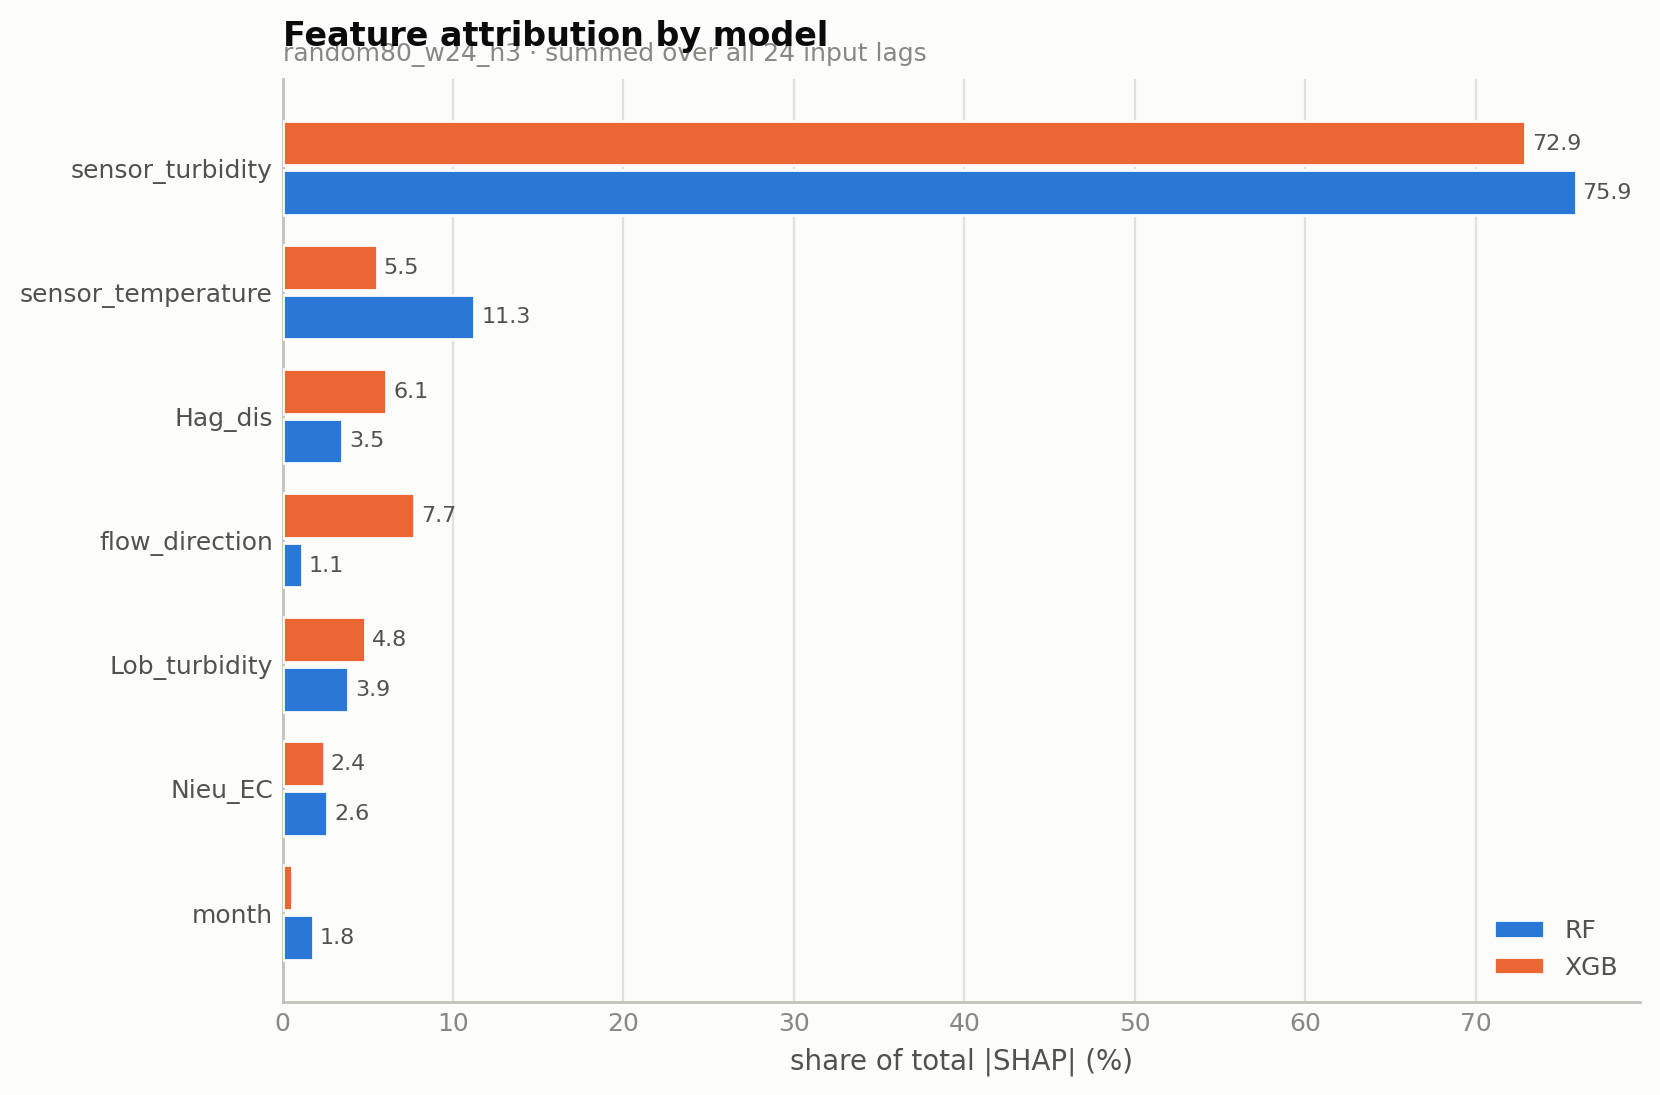

  -> trained_models_random80/shap/fig_shap_beeswarm_RF_random80_w24_h3.png


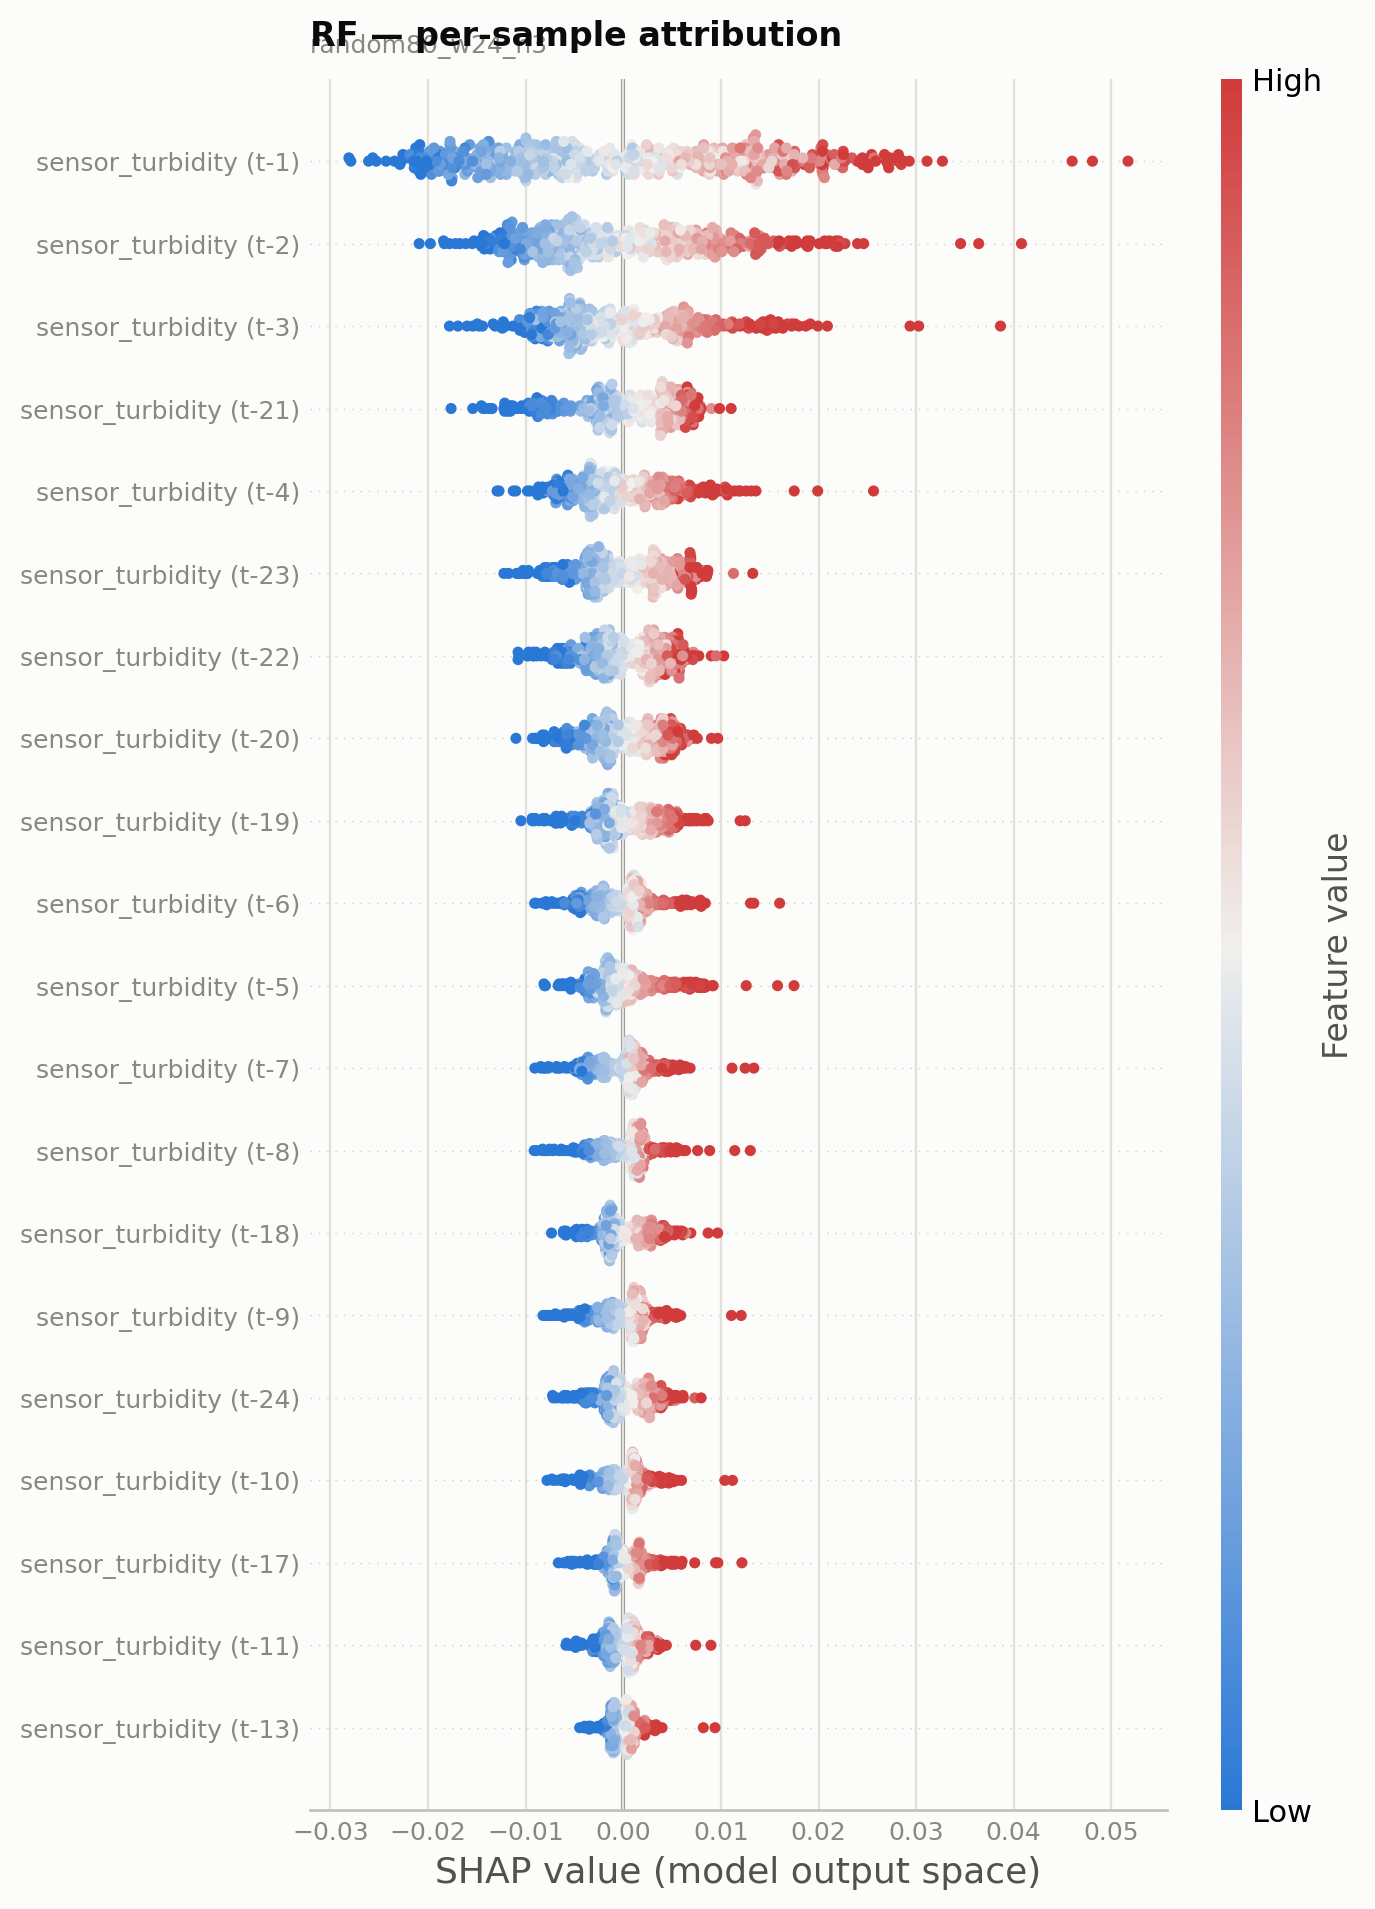

  -> trained_models_random80/shap/fig_shap_beeswarm_XGB_random80_w24_h3.png


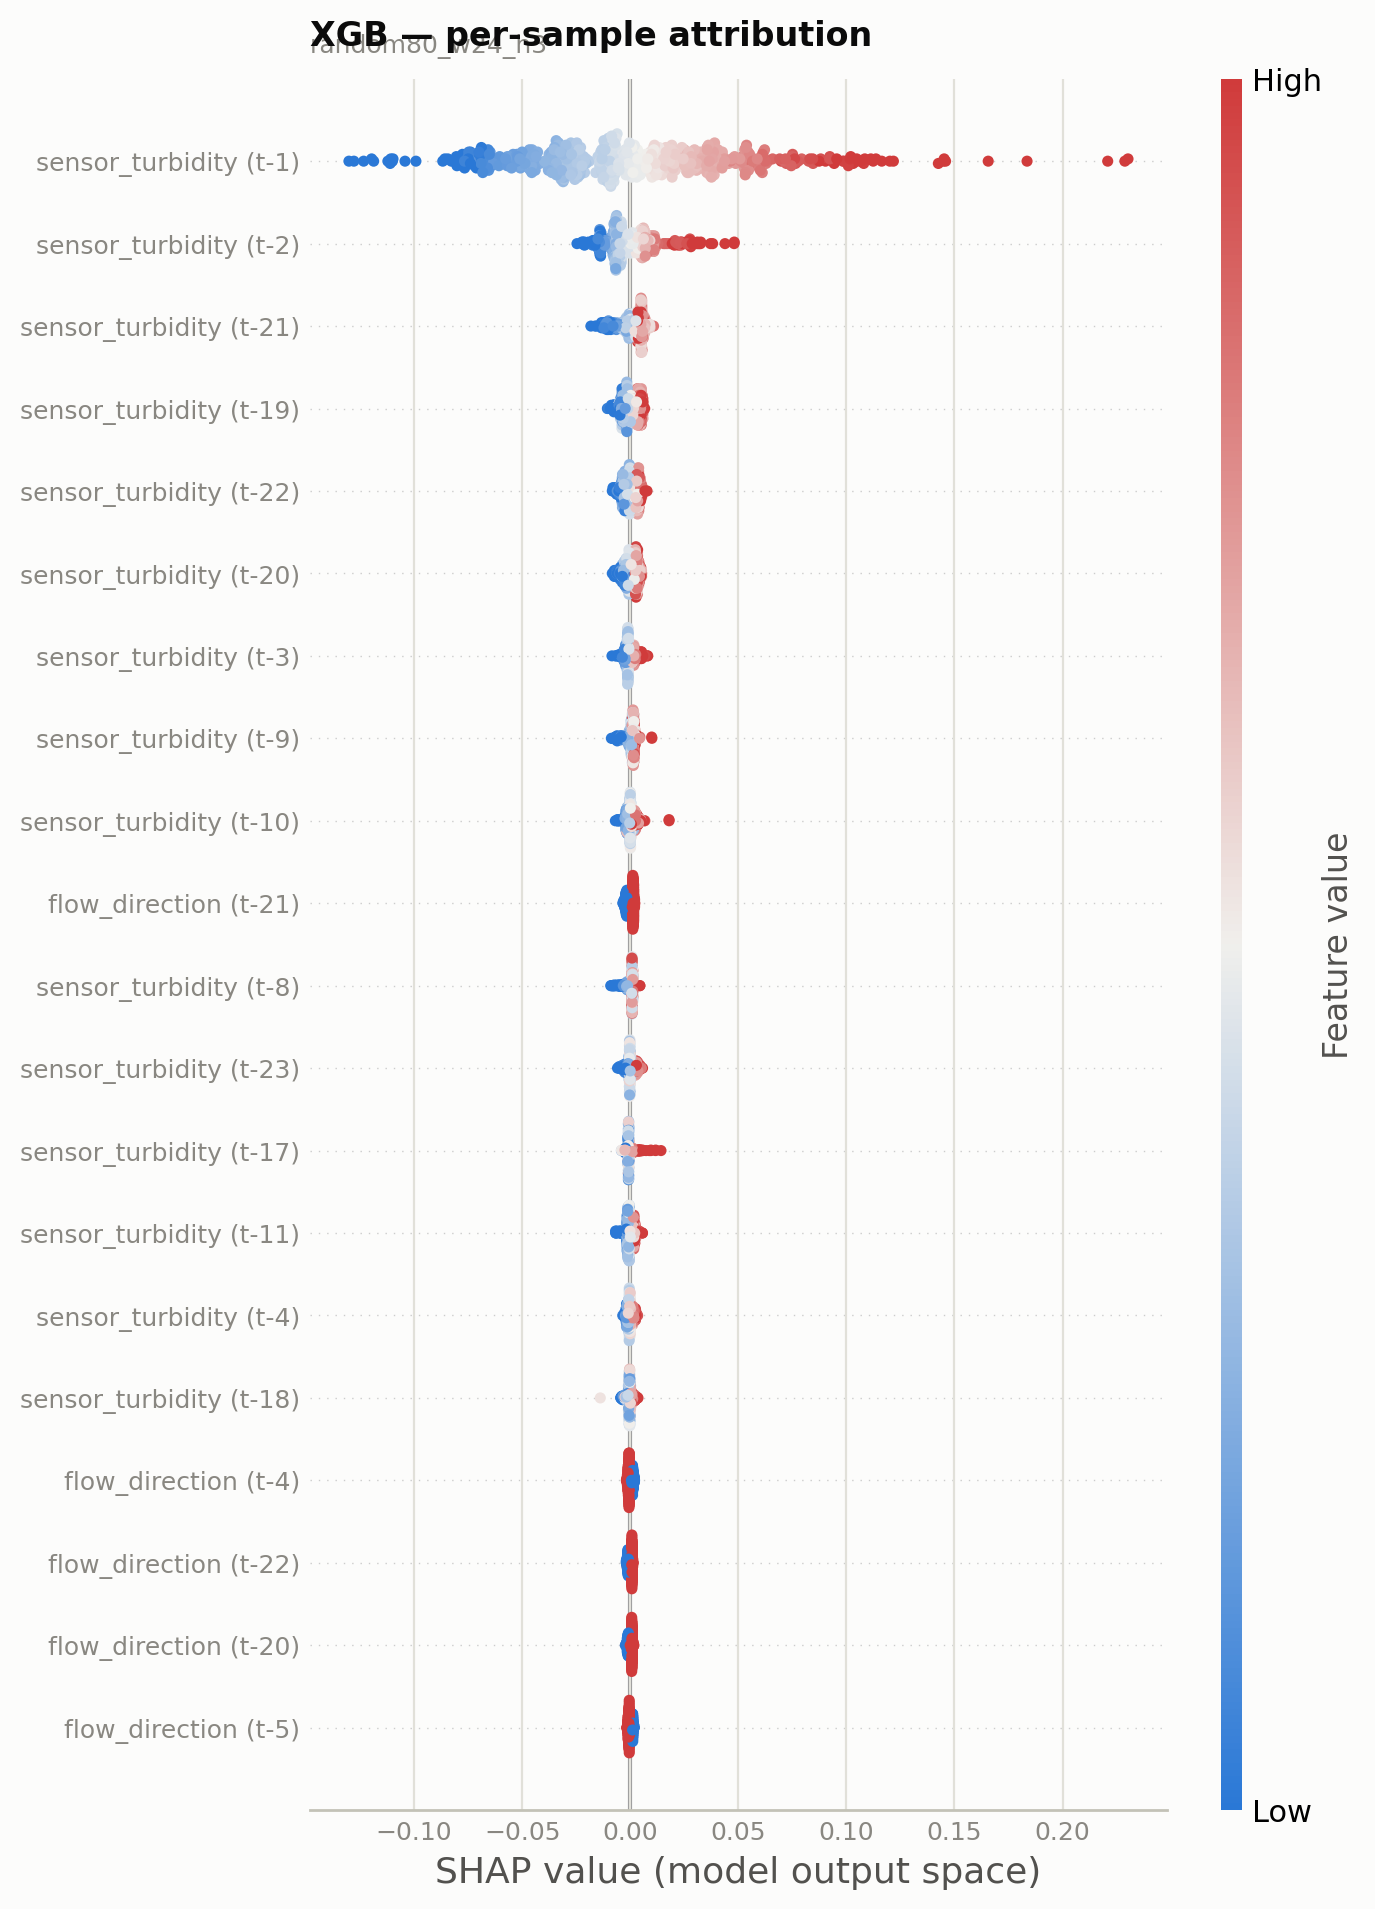

  -> trained_models_random80/shap/fig_shap_lagprofile_random80_w24_h3.png


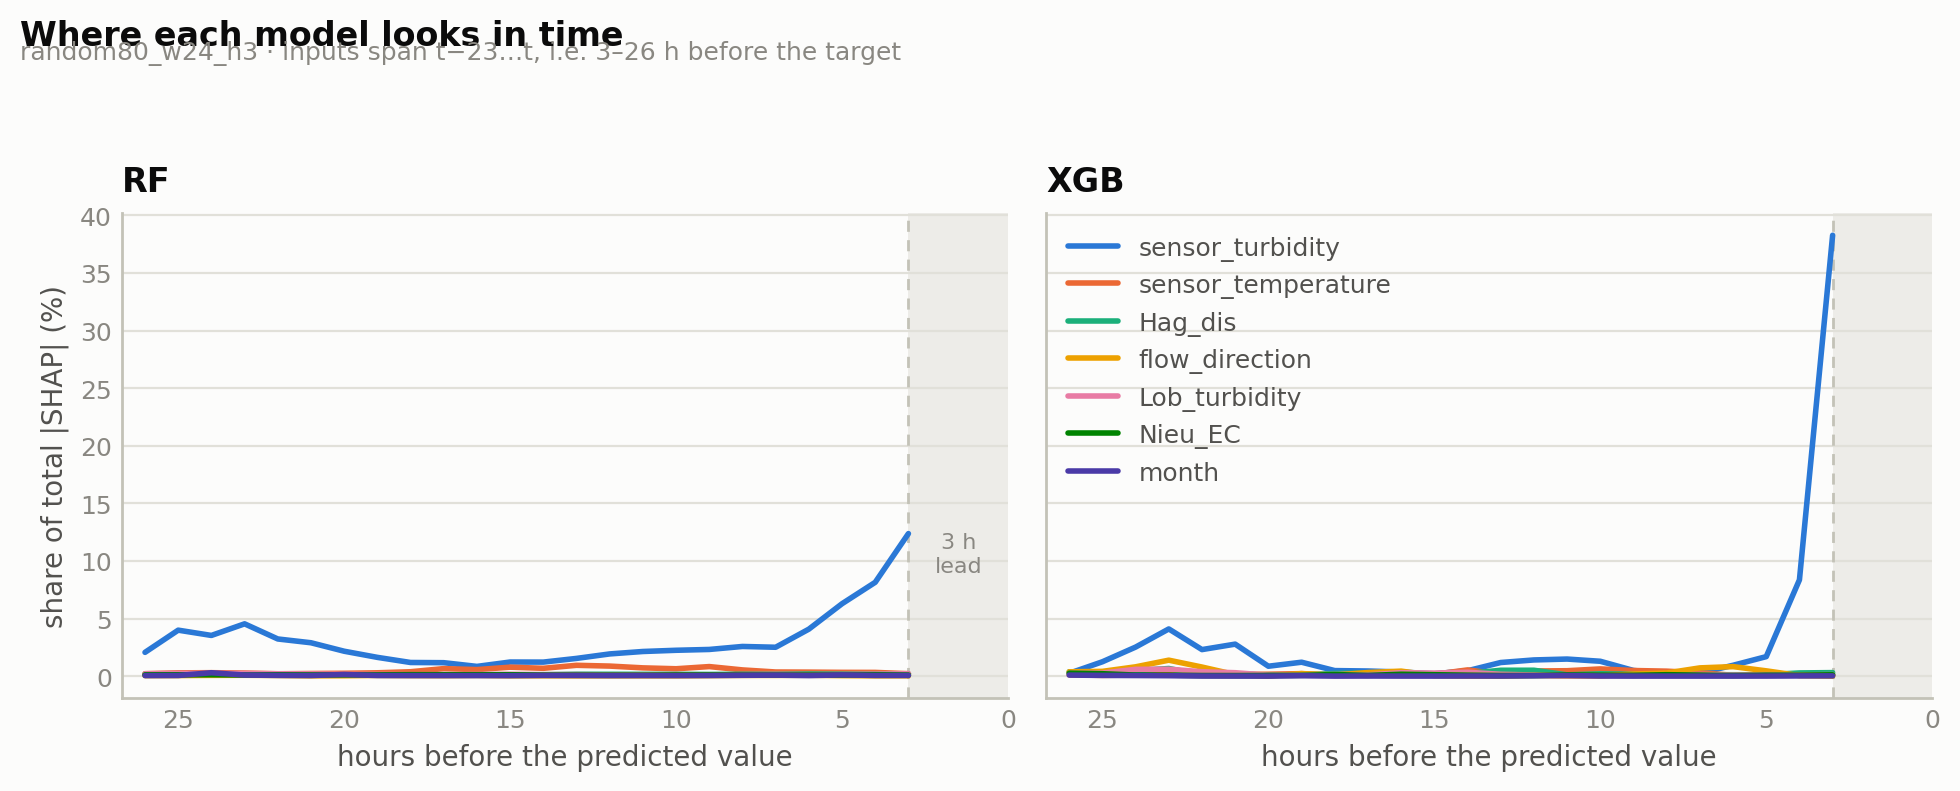


Done.


In [ ]:
!pip -q install shap
import shap_feature_importance
res = shap_feature_importance.run(horizon=3, window=24, split="random")

## **BOOTSTRAP of the best models**

In [ ]:
from google.colab import drive
import os, shutil, sys
drive.mount("/content/drive", force_remount=True)

PROJ = ("/content/drive/My Drive/Colab Notebooks/"
        "Turbidity model - Hang_s thesis/ML_turbidity_prediction-main")
WORK = "/content/work"

IGNORE = shutil.ignore_patterns(
    ".git", "__pycache__", "*.pyc", ".ipynb_checkpoints",
    "trained_models_*", "Superseded","data")
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree(PROJ, WORK, ignore=IGNORE)

# ...then bring in just the one run you're explaining
shutil.copytree(os.path.join(PROJ, "trained_models_random80"),
                os.path.join(WORK, "trained_models_random80"),
                dirs_exist_ok=True)         # skip all of them...
shutil.rmtree(WORK, ignore_errors=True)
shutil.copytree(PROJ, WORK, ignore=IGNORE)

# ...then bring in just the one run you're explaining
shutil.copytree(os.path.join(PROJ, "trained_models_random80"),
                os.path.join(WORK, "trained_models_random80"),
                dirs_exist_ok=True)
os.chdir(WORK); sys.path.insert(0, WORK)
print(os.getcwd(), os.path.exists("notebooks/FM_LSTM.csv"))

Mounted at /content/drive
/content/work True


FEATURE_COLUMNS (7): ['sensor_turbidity', 'Hag_dis', 'sensor_temperature', 'Nieu_EC', 'Lob_turbidity', 'flow_direction', 'month']
tree lags: L1-2-3-20-21-22-23-24   horizons: (1, 2, 3, 4, 5, 6)   split: random
resampling: 75% without replacement   B = 10   aligned splits: True
model fits: 132 (cached fits reused)
PREFLIGHT: hyperparameters
  RF params <- random80_w24-treeL1-2-3-20-21-22-23-24_h1_f7   (7 features, 56 columns)
  XGB params <- random80_w24-treeL1-2-3-20-21-22-23-24_h1_f7   (7 features, 56 columns)
  RF params <- random80_w24-treeL1-2-3-20-21-22-23-24_h2_f7   (7 features, 56 columns)
  XGB params <- random80_w24-treeL1-2-3-20-21-22-23-24_h2_f7   (7 features, 56 columns)
  RF params <- random80_w24-treeL1-2-3-20-21-22-23-24_h3_f7   (7 features, 56 columns)
  XGB params <- random80_w24-treeL1-2-3-20-21-22-23-24_h3_f7   (7 features, 56 columns)
  RF params <- random80_w24-treeL1-2-3-20-21-22-23-24_h4_f7   (7 features, 56 columns)
  XGB params <- random80_w24-treeL1-2-3-20-21-

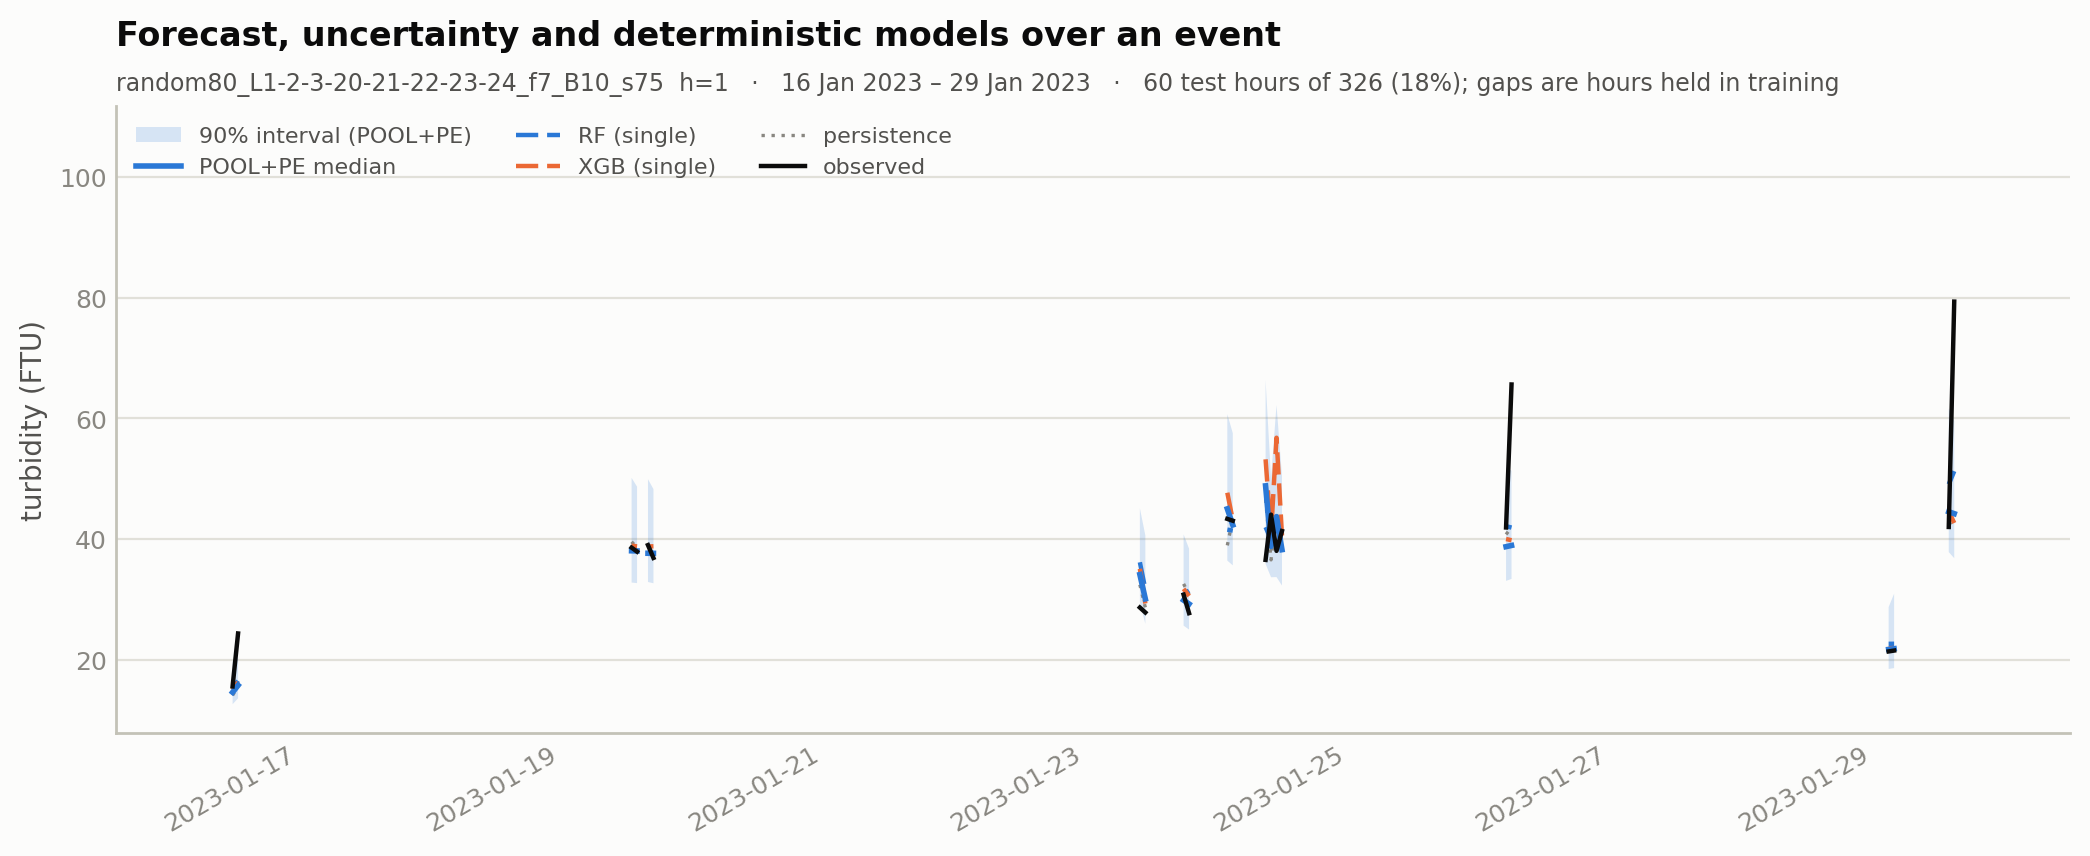


HORIZON 2   (6,937 evaluated rows)

--- RF single ---
  RF single model: full data, OOB residuals, 27,748 residuals

--- RF ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 38s)
    member 2/10  (75.0% unique, 6,937 held out, 36s)
    member 3/10  (75.0% unique, 6,937 held out, 36s)
    member 4/10  (75.0% unique, 6,937 held out, 37s)
    member 5/10  (75.0% unique, 6,937 held out, 36s)
    member 6/10  (75.0% unique, 6,937 held out, 36s)
    member 7/10  (75.0% unique, 6,937 held out, 37s)
    member 8/10  (75.0% unique, 6,937 held out, 40s)
    member 9/10  (75.0% unique, 6,937 held out, 38s)
    member 10/10  (75.0% unique, 6,937 held out, 37s)
  + process error: 50 draws per member

--- XGB single ---
  XGB single model: 80% of data, 5,550 calibration rows, 5,550 residuals

--- XGB ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 9s)
    member 2/10  (75.0% unique, 6,937 held out, 5s)
    member 3/10  (75.0% unique, 6,937 held out, 9

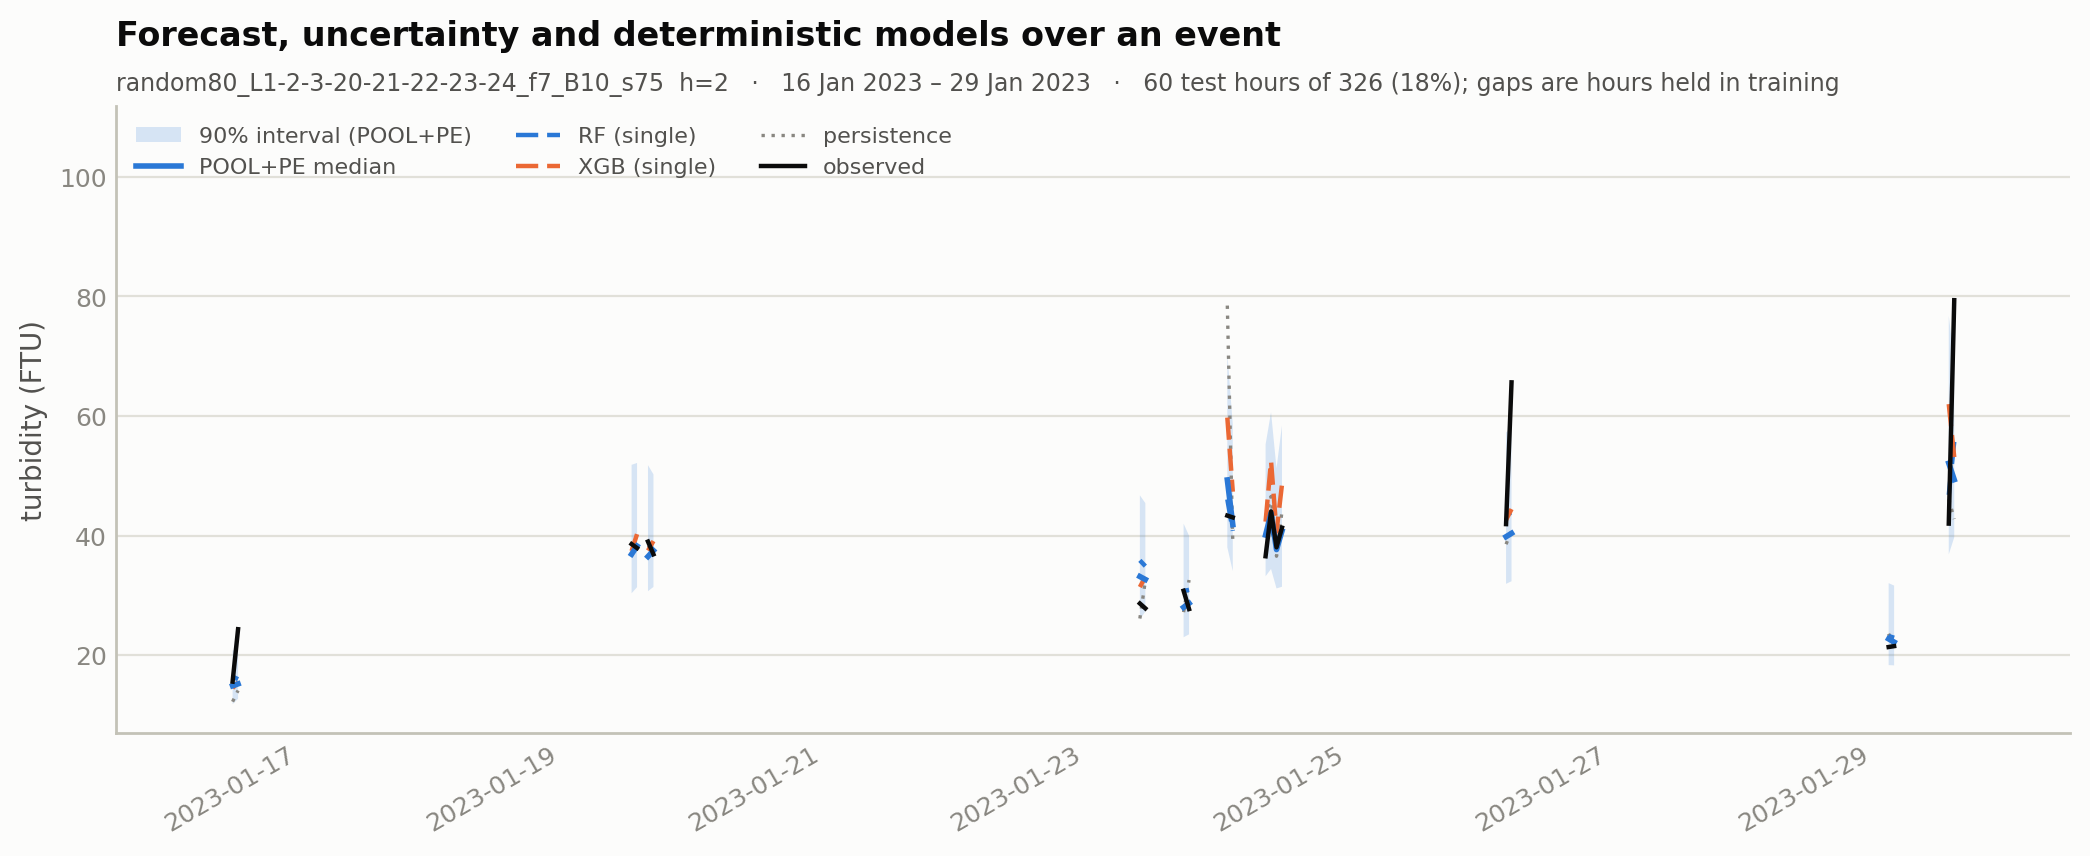


HORIZON 3   (6,937 evaluated rows)

--- RF single ---
  RF single model: full data, OOB residuals, 27,748 residuals

--- RF ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 36s)
    member 2/10  (75.0% unique, 6,937 held out, 35s)
    member 3/10  (75.0% unique, 6,937 held out, 38s)
    member 4/10  (75.0% unique, 6,937 held out, 35s)
    member 5/10  (75.0% unique, 6,937 held out, 35s)
    member 6/10  (75.0% unique, 6,937 held out, 37s)
    member 7/10  (75.0% unique, 6,937 held out, 36s)
    member 8/10  (75.0% unique, 6,937 held out, 35s)
    member 9/10  (75.0% unique, 6,937 held out, 36s)
    member 10/10  (75.0% unique, 6,937 held out, 37s)
  + process error: 50 draws per member

--- XGB single ---
  XGB single model: 80% of data, 5,550 calibration rows, 5,550 residuals

--- XGB ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 9s)
    member 2/10  (75.0% unique, 6,937 held out, 5s)
    member 3/10  (75.0% unique, 6,937 held out, 9

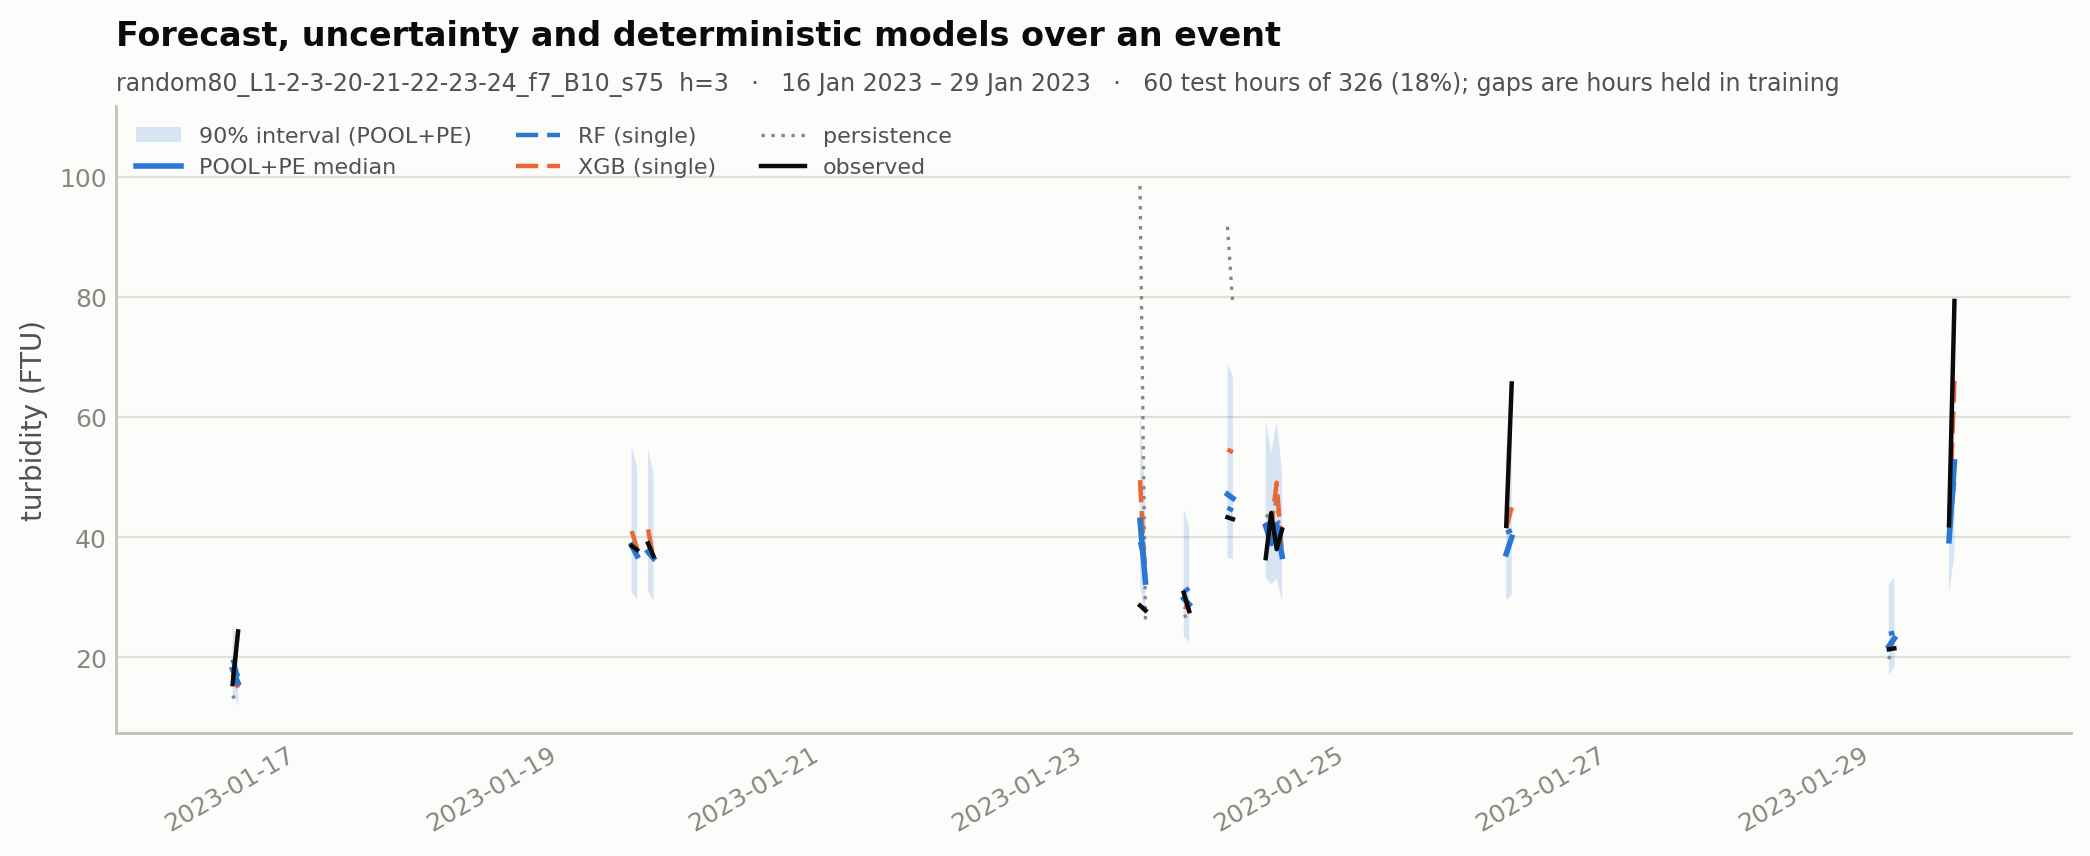


HORIZON 4   (6,937 evaluated rows)

--- RF single ---
  RF single model: full data, OOB residuals, 27,748 residuals

--- RF ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 36s)
    member 2/10  (75.0% unique, 6,937 held out, 40s)
    member 3/10  (75.0% unique, 6,937 held out, 36s)
    member 4/10  (75.0% unique, 6,937 held out, 35s)
    member 5/10  (75.0% unique, 6,937 held out, 35s)
    member 6/10  (75.0% unique, 6,937 held out, 38s)
    member 7/10  (75.0% unique, 6,937 held out, 35s)
    member 8/10  (75.0% unique, 6,937 held out, 35s)
    member 9/10  (75.0% unique, 6,937 held out, 37s)
    member 10/10  (75.0% unique, 6,937 held out, 35s)
  + process error: 50 draws per member

--- XGB single ---
  XGB single model: 80% of data, 5,550 calibration rows, 5,550 residuals

--- XGB ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 8s)
    member 2/10  (75.0% unique, 6,937 held out, 5s)
    member 3/10  (75.0% unique, 6,937 held out, 8

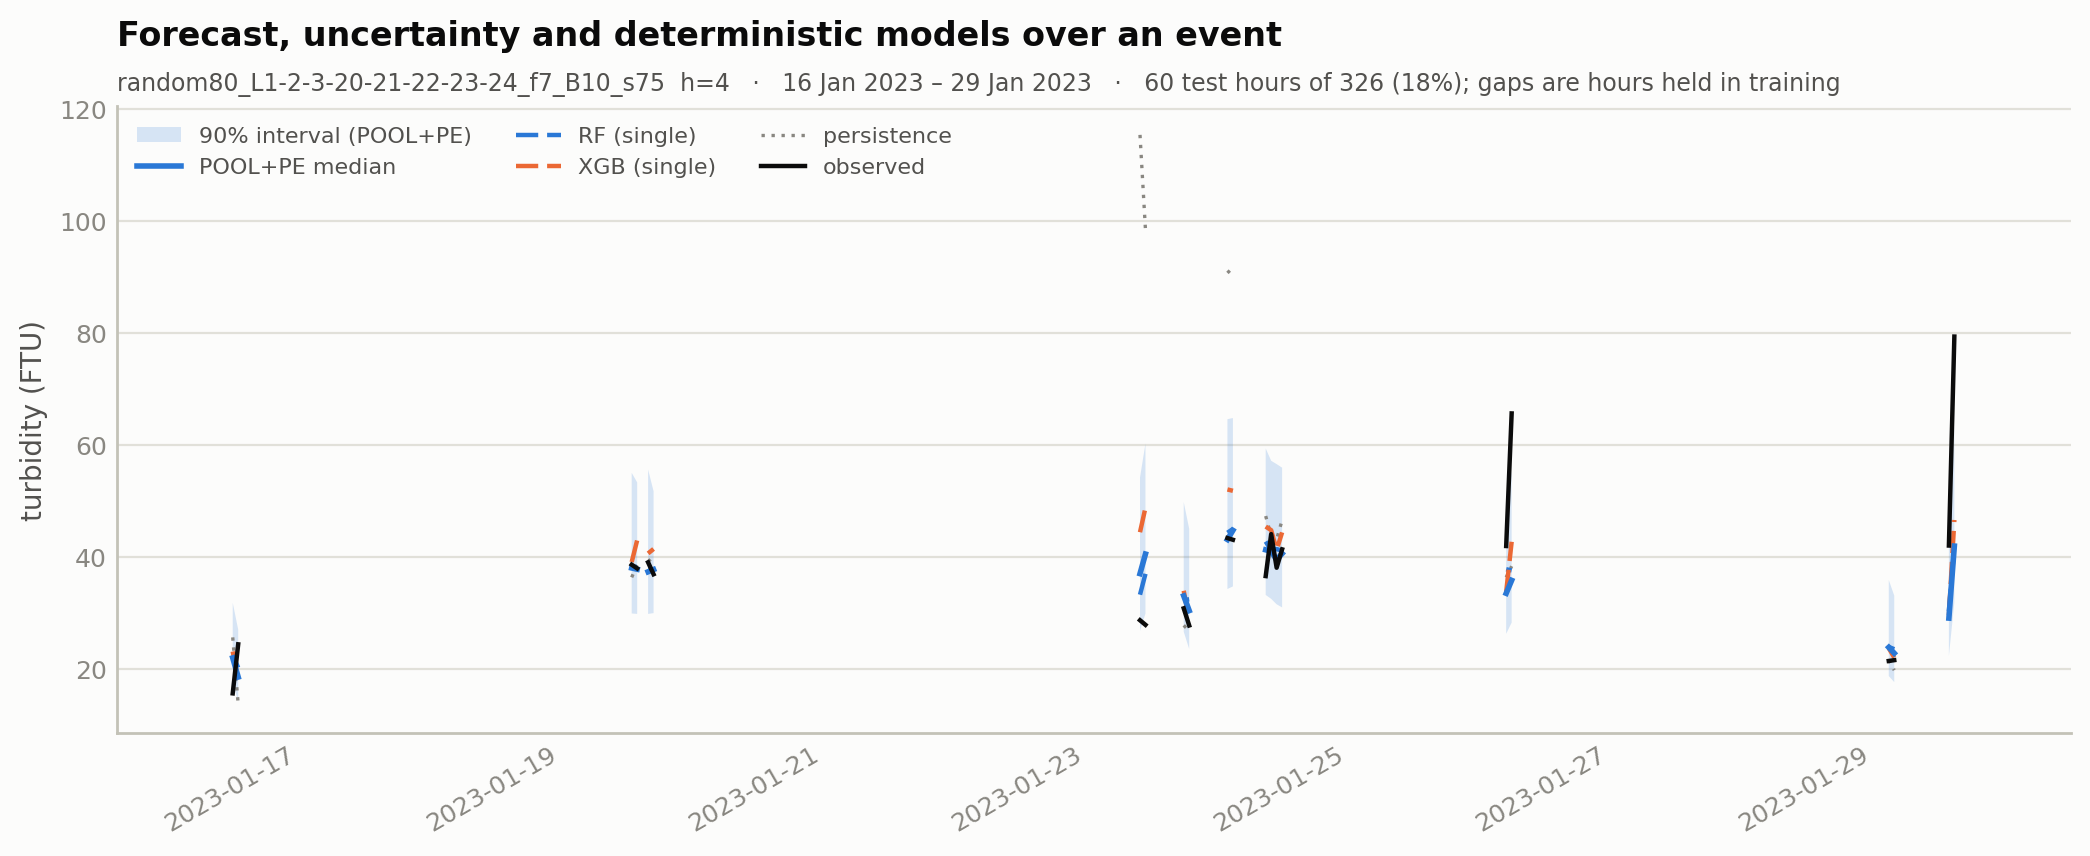


HORIZON 5   (6,937 evaluated rows)

--- RF single ---
  RF single model: full data, OOB residuals, 27,749 residuals

--- RF ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 35s)
    member 2/10  (75.0% unique, 6,937 held out, 35s)
    member 3/10  (75.0% unique, 6,937 held out, 38s)
    member 4/10  (75.0% unique, 6,937 held out, 35s)
    member 5/10  (75.0% unique, 6,937 held out, 39s)
    member 6/10  (75.0% unique, 6,937 held out, 37s)
    member 7/10  (75.0% unique, 6,937 held out, 35s)
    member 8/10  (75.0% unique, 6,937 held out, 35s)
    member 9/10  (75.0% unique, 6,937 held out, 36s)
    member 10/10  (75.0% unique, 6,937 held out, 37s)
  + process error: 50 draws per member

--- XGB single ---
  XGB single model: 80% of data, 5,550 calibration rows, 5,550 residuals

--- XGB ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 9s)
    member 2/10  (75.0% unique, 6,937 held out, 5s)
    member 3/10  (75.0% unique, 6,937 held out, 9

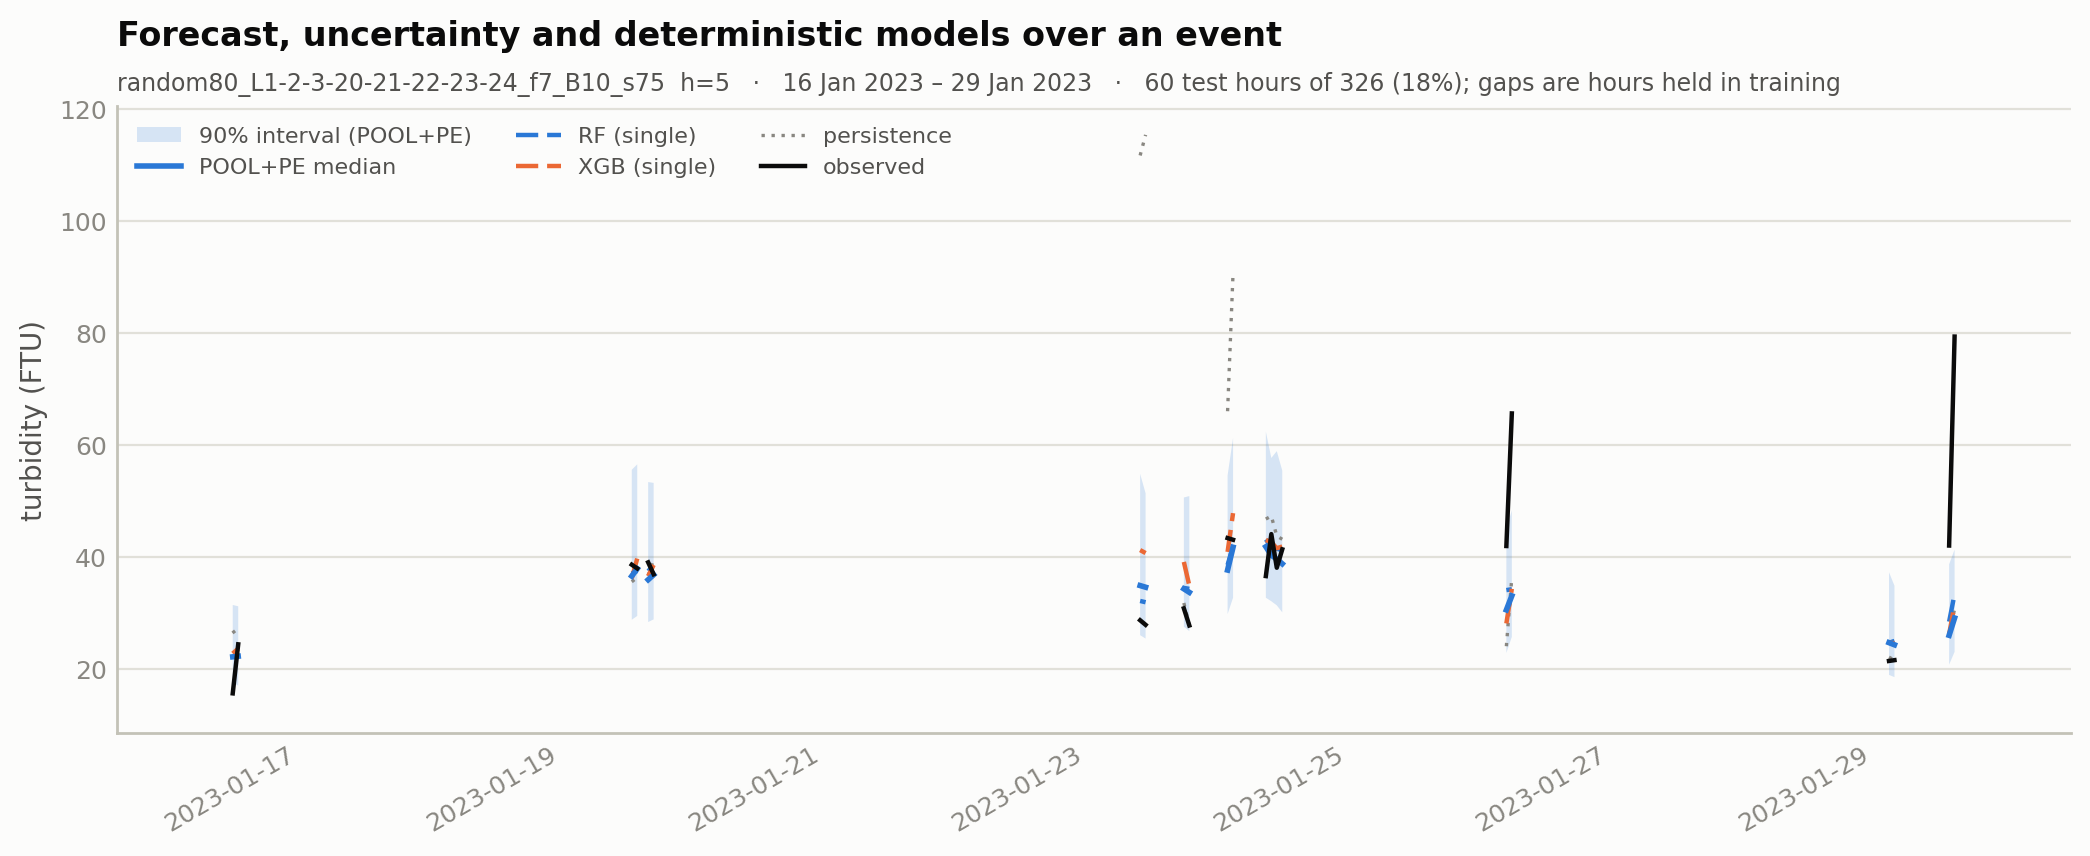


HORIZON 6   (6,937 evaluated rows)

--- RF single ---
  RF single model: full data, OOB residuals, 27,749 residuals

--- RF ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 35s)
    member 2/10  (75.0% unique, 6,937 held out, 35s)
    member 3/10  (75.0% unique, 6,937 held out, 38s)
    member 4/10  (75.0% unique, 6,937 held out, 36s)
    member 5/10  (75.0% unique, 6,937 held out, 35s)
    member 6/10  (75.0% unique, 6,937 held out, 37s)
    member 7/10  (75.0% unique, 6,937 held out, 36s)
    member 8/10  (75.0% unique, 6,937 held out, 35s)
    member 9/10  (75.0% unique, 6,937 held out, 35s)
    member 10/10  (75.0% unique, 6,937 held out, 38s)
  + process error: 50 draws per member

--- XGB single ---
  XGB single model: 80% of data, 5,550 calibration rows, 5,550 residuals

--- XGB ensemble: 10 members ---
    member 1/10  (75.0% unique, 6,937 held out, 9s)
    member 2/10  (75.0% unique, 6,937 held out, 12s)
    member 3/10  (75.0% unique, 6,937 held out, 

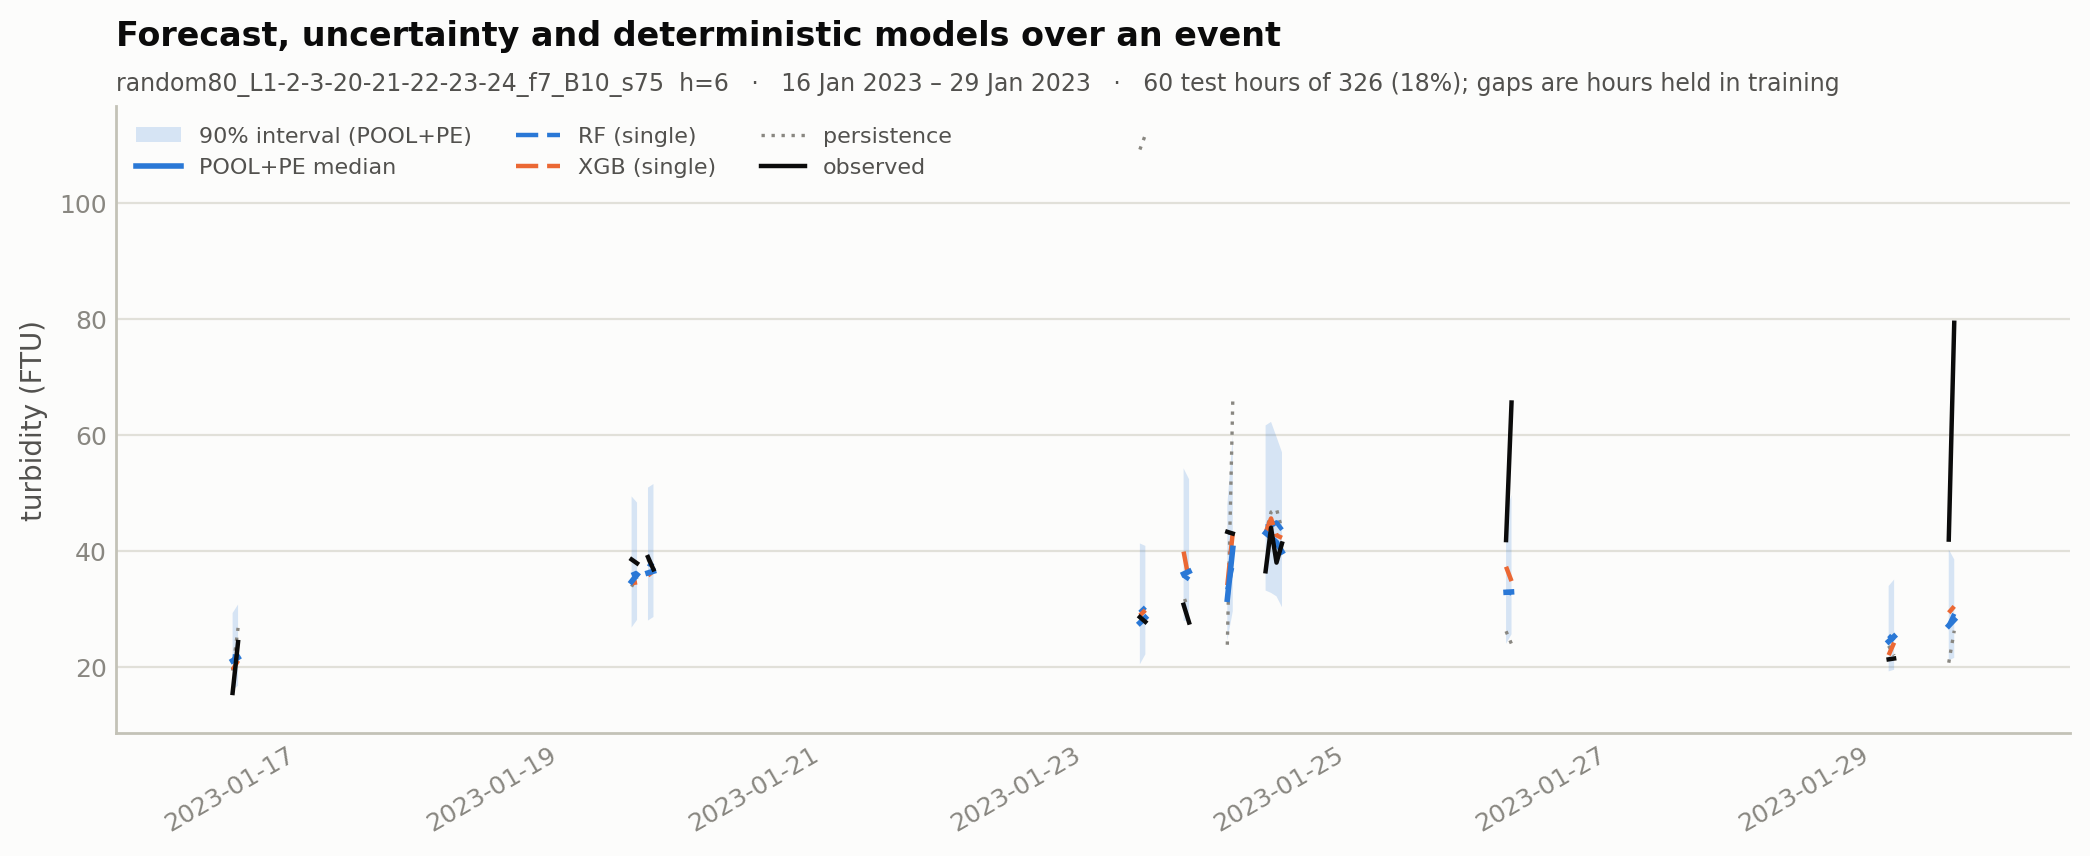


MULTI-HORIZON ENSEMBLE UQ   [random80_L1-2-3-20-21-22-23-24_f7_B10_s75]
 horizon       model  kind  B   RMSE    MAE  SS_vs_persistence  CRPS_fair  CRPS_biased  coverage90  width90_FTU
       1 persistence point  1 3.1593 1.7299             0.0000     1.7299       1.7299         NaN          NaN
       1     POOL+PE  band 20 3.1795 1.7031            -0.0128     1.2507       1.2519      0.9086       7.2738
       1        RF+R  band  1 3.1946 1.7258            -0.0225     1.2786       1.2798      0.8972       7.1519
       1       XGB+R  band  1 3.1954 1.7077            -0.0230     1.2712       1.2724      0.8868       6.8067
       1    POOL ens  band 20 3.1955 1.6671            -0.0231     1.5009       1.5108      0.1730       0.9098
       1      XGB+PE  band 10 3.2083 1.7117            -0.0313     1.2675       1.2699      0.8889       6.9646
       1   RF single point  1 3.2098 1.7036            -0.0323     1.7036       1.7036         NaN          NaN
       1  XGB single point  1 3

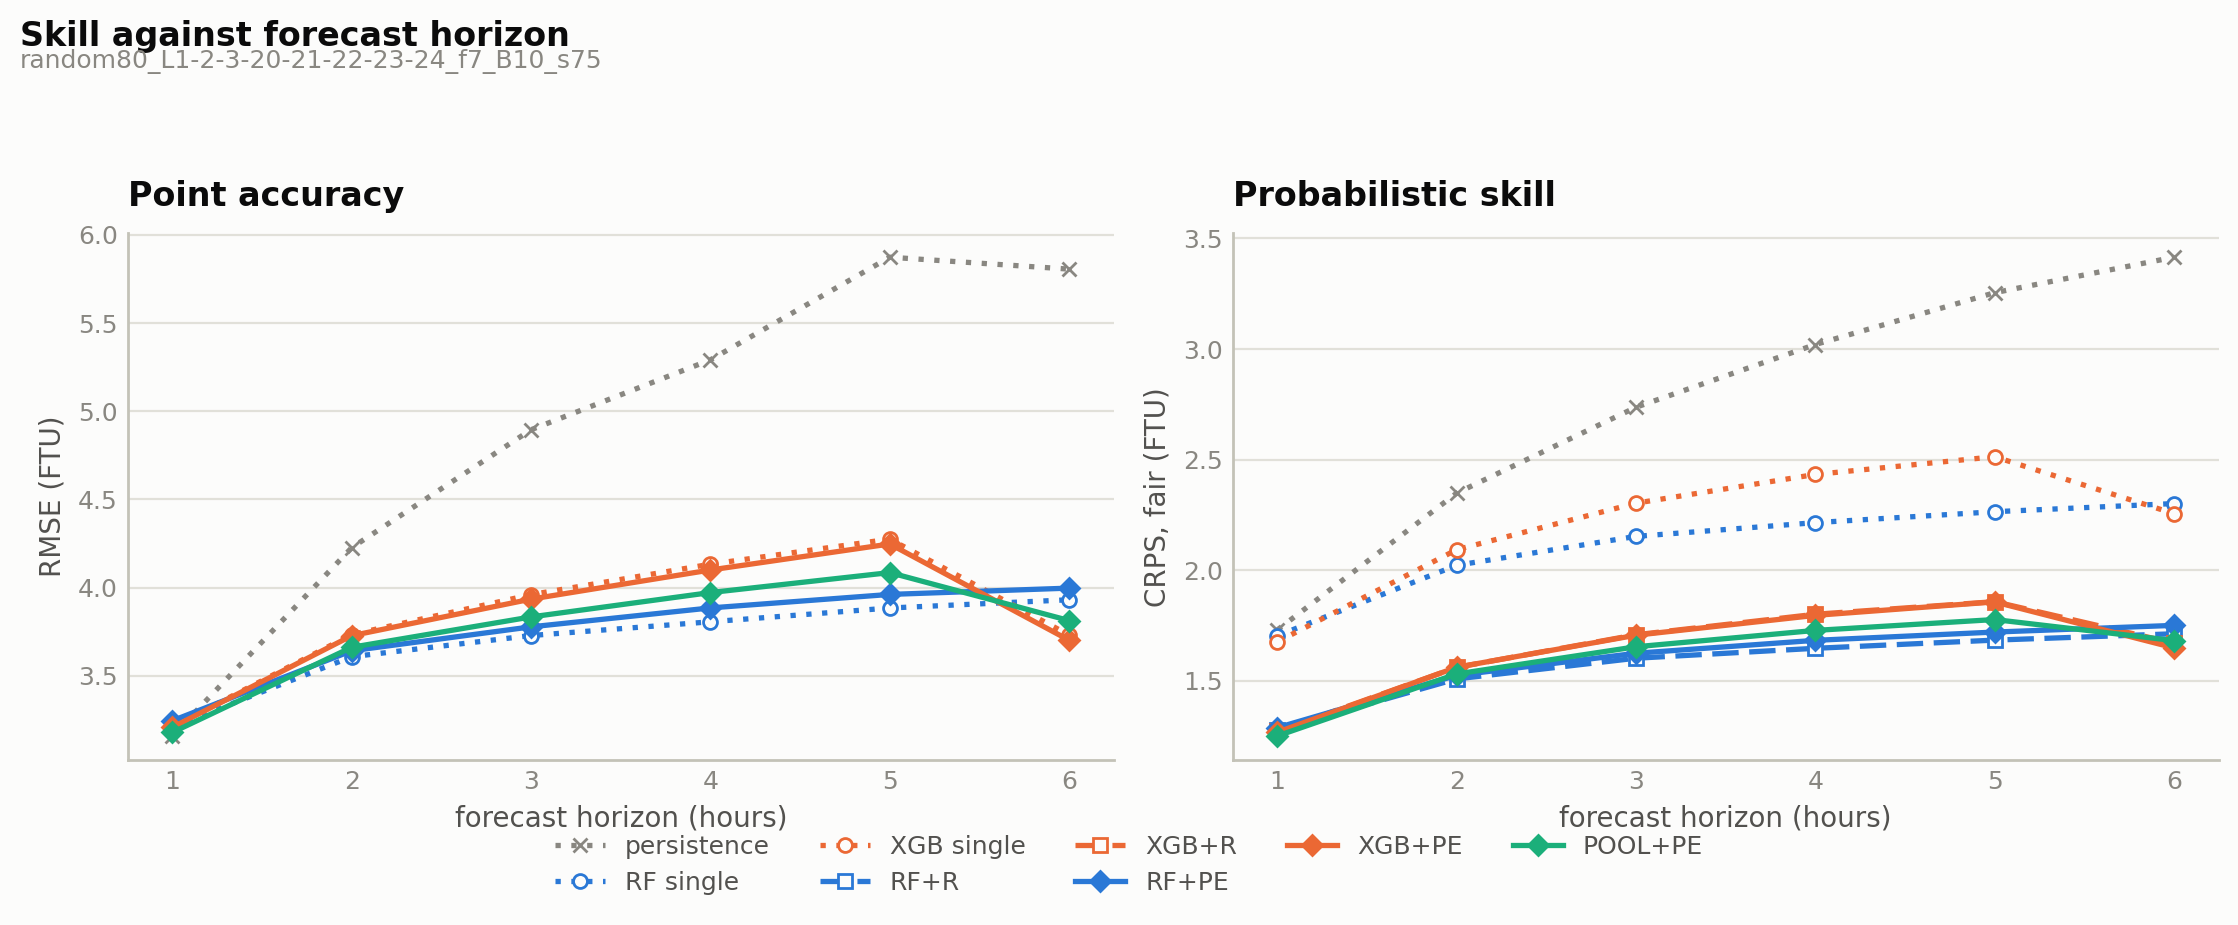

  scatter: XGB+PE at h = 6
  -> trained_models_random80/uq_horizons/fig_h_scatter_random80_L1-2-3-20-21-22-23-24_f7_B10_s75.png


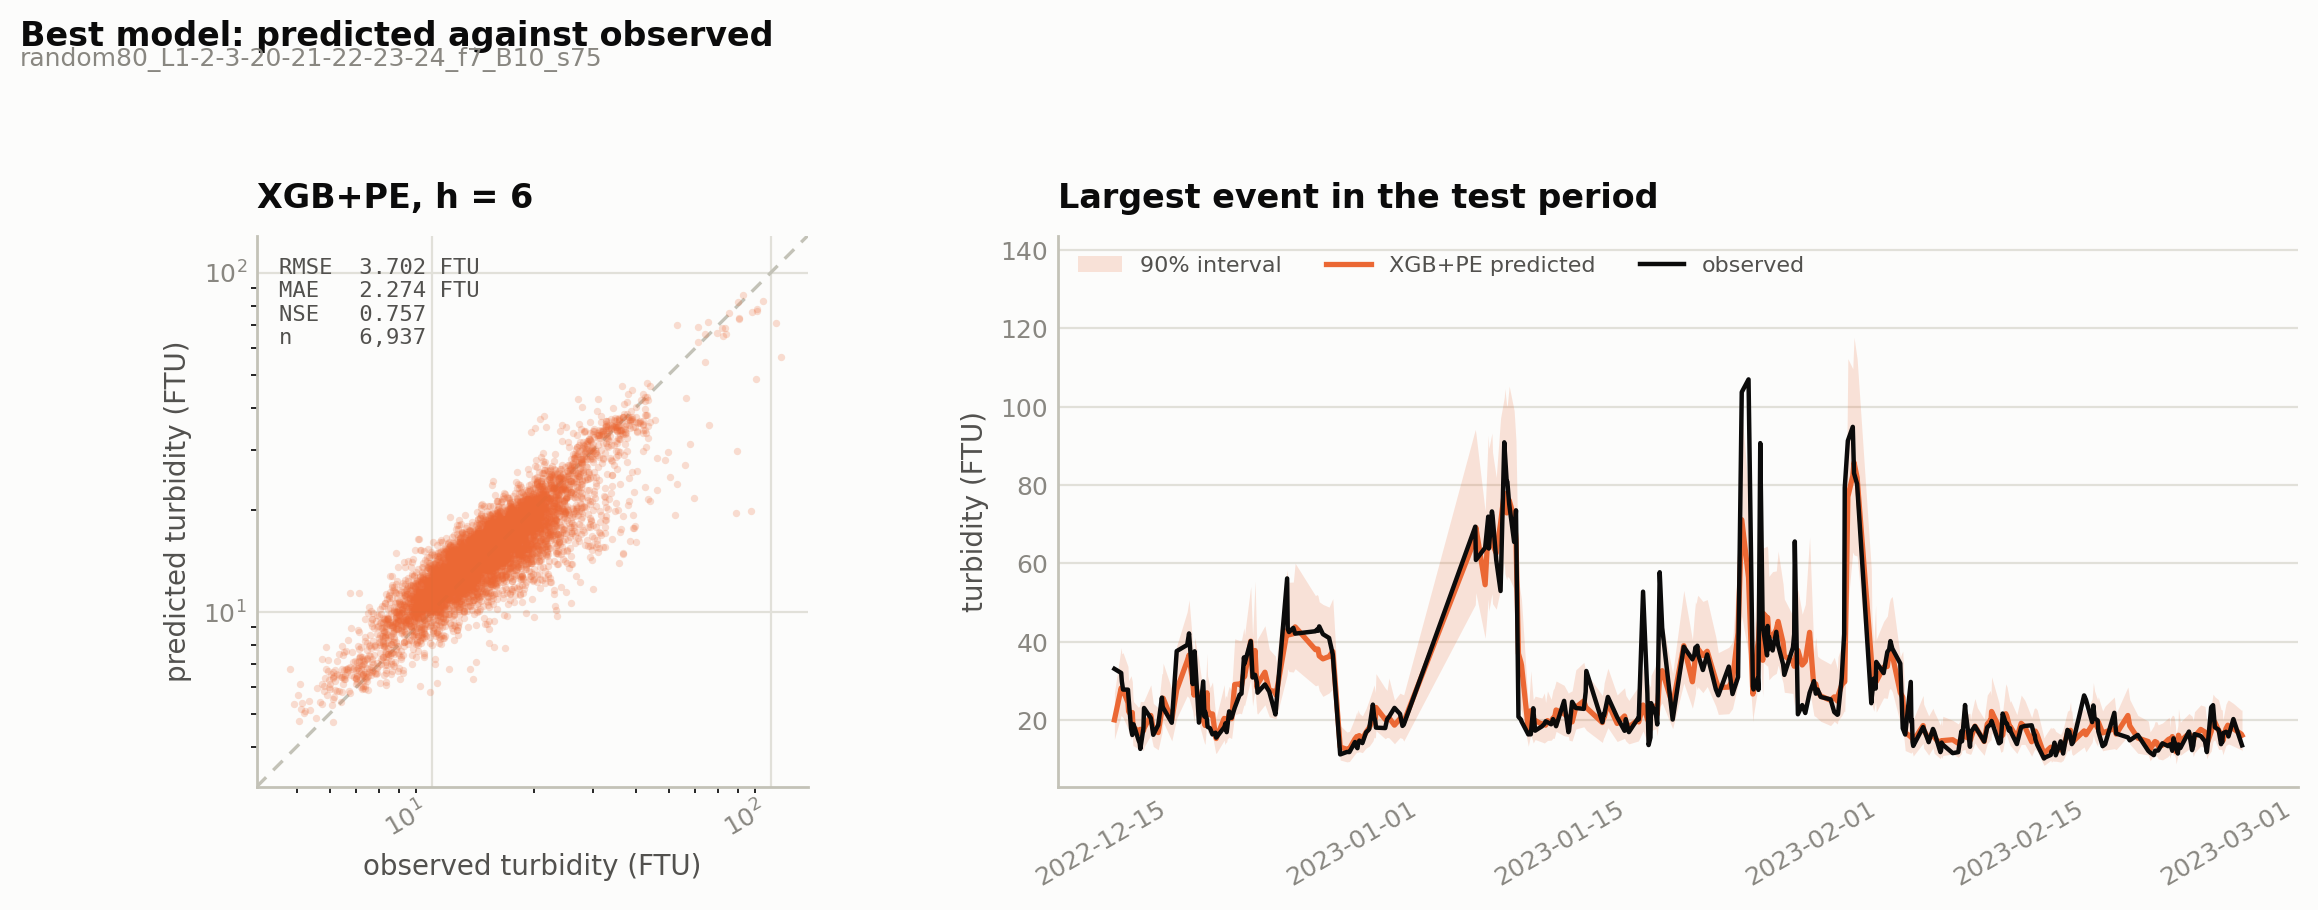


Done in 50.3 min -> trained_models_random80/uq_horizons
FEATURE_COLUMNS (7): ['sensor_turbidity', 'Hag_dis', 'sensor_temperature', 'Nieu_EC', 'Lob_turbidity', 'flow_direction', 'month']
tree lags: L1-2-3-20-21-22-23-24   horizon: 6   split: random
resampling: 75% without replacement
Loaded 37,200 rows  (2019-12-01 00:00:00 -> 2024-02-27 23:00:00)
  valid: 35,178   invalid/gap-filled: 2,022

RANDOM split (seed 42)
  train: 27,749 windows   (2020-01-02 05:00:00 -> 2024-02-26 20:00:00)
  test : 6,938 windows   (2020-01-02 09:00:00 -> 2024-02-26 19:00:00)   = 20.0%
  NOTE: test windows are interleaved with training windows. Every test window has temporal neighbours in training with near-identical inputs and targets. Read this as reconstruction, not forecasting.
  scaler[sensor_turbidity]: min=1.5360  max=5.1259
  scaler[Hag_dis]: min=-41.9117  max=1380.6233
  scaler[sensor_temperature]: min=3.0465  max=26.0446
  scaler[Nieu_EC]: min=21000000.0000  max=66000000.0000
  scaler[Lob_turbidity]

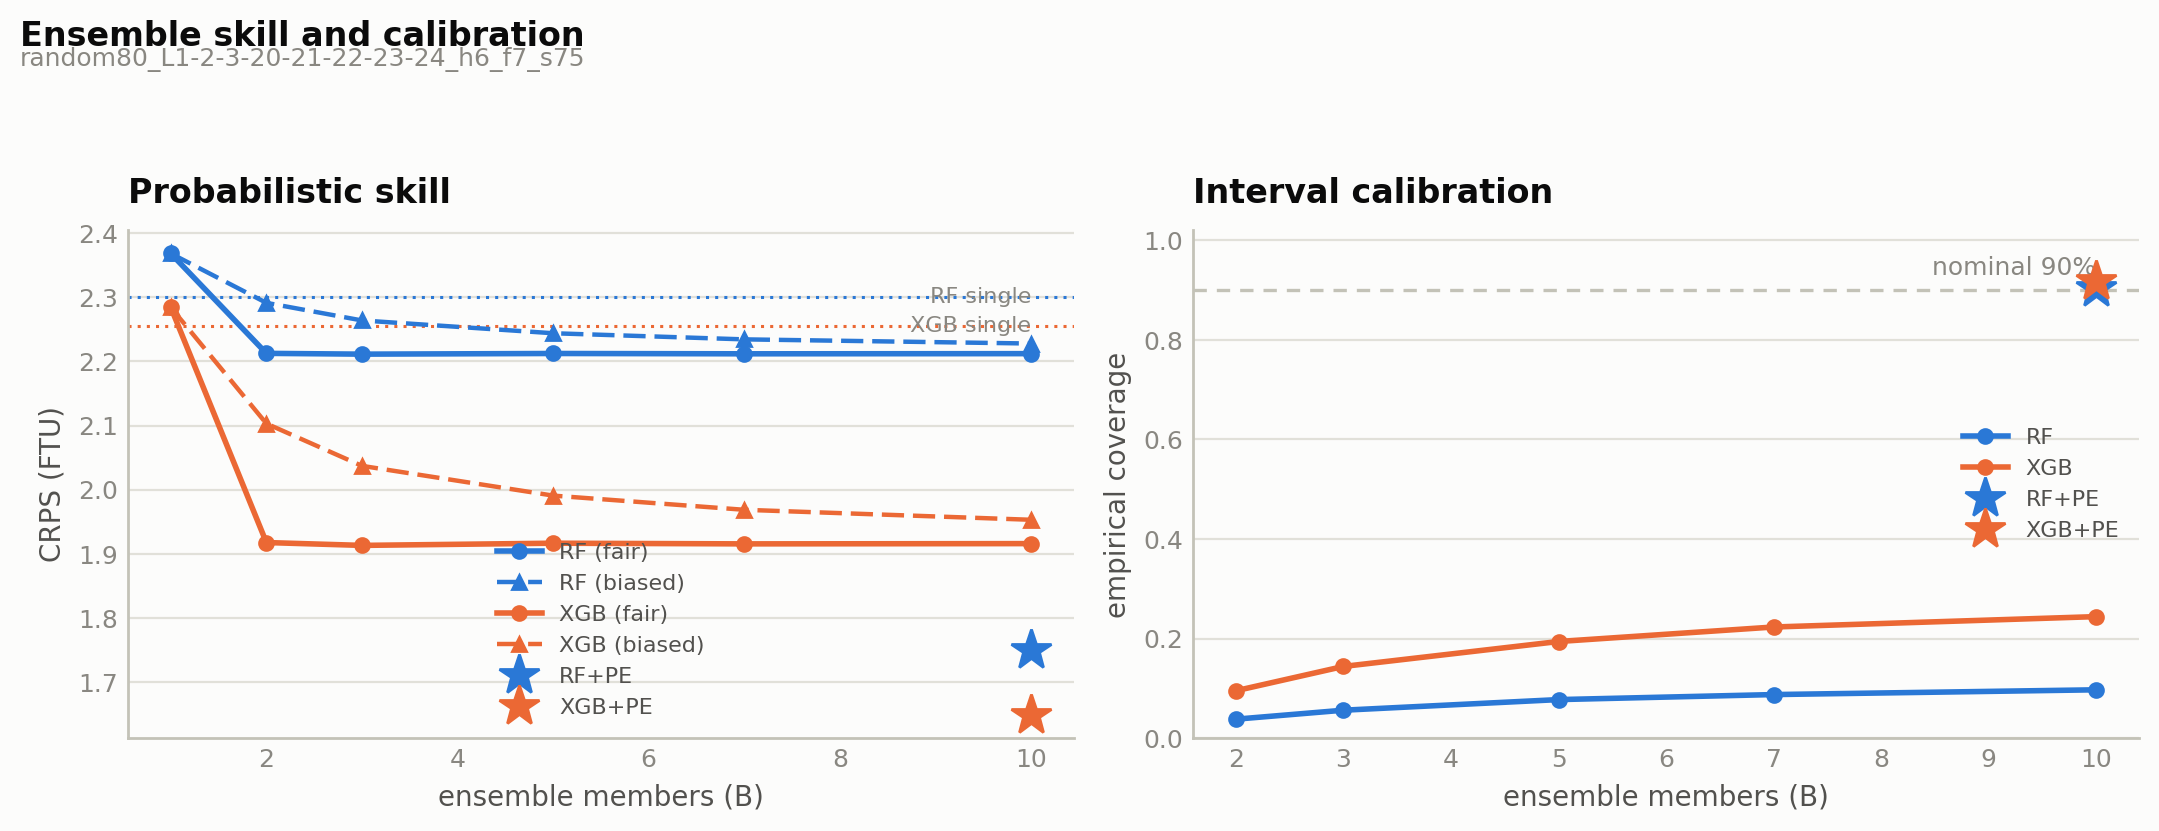

  -> trained_models_random80/uq/fig_uq_reliability_random80_L1-2-3-20-21-22-23-24_h6_f7_s75.png


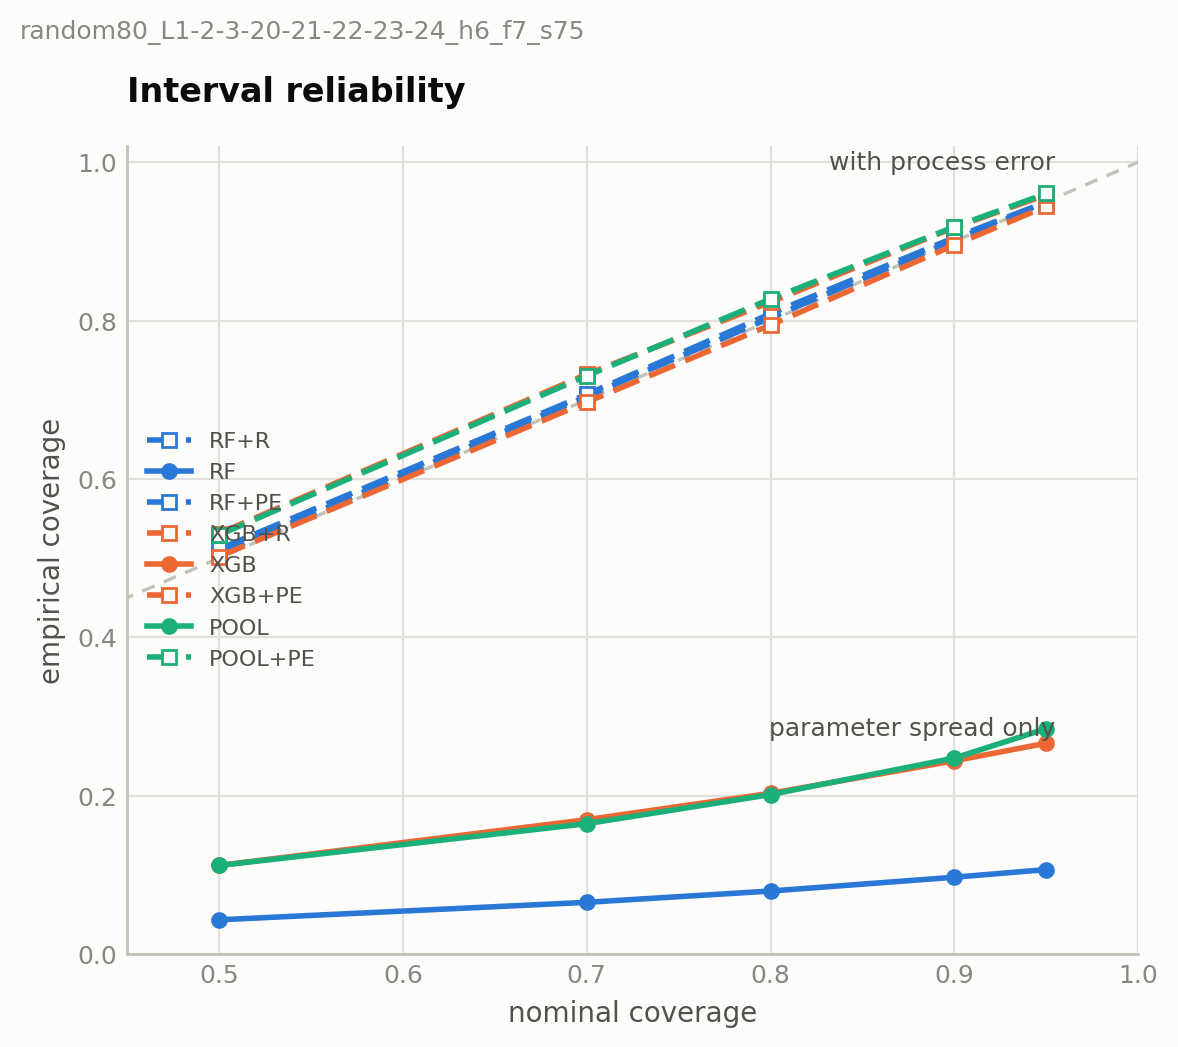

  -> trained_models_random80/uq/fig_uq_series_random80_L1-2-3-20-21-22-23-24_h6_f7_s75.png


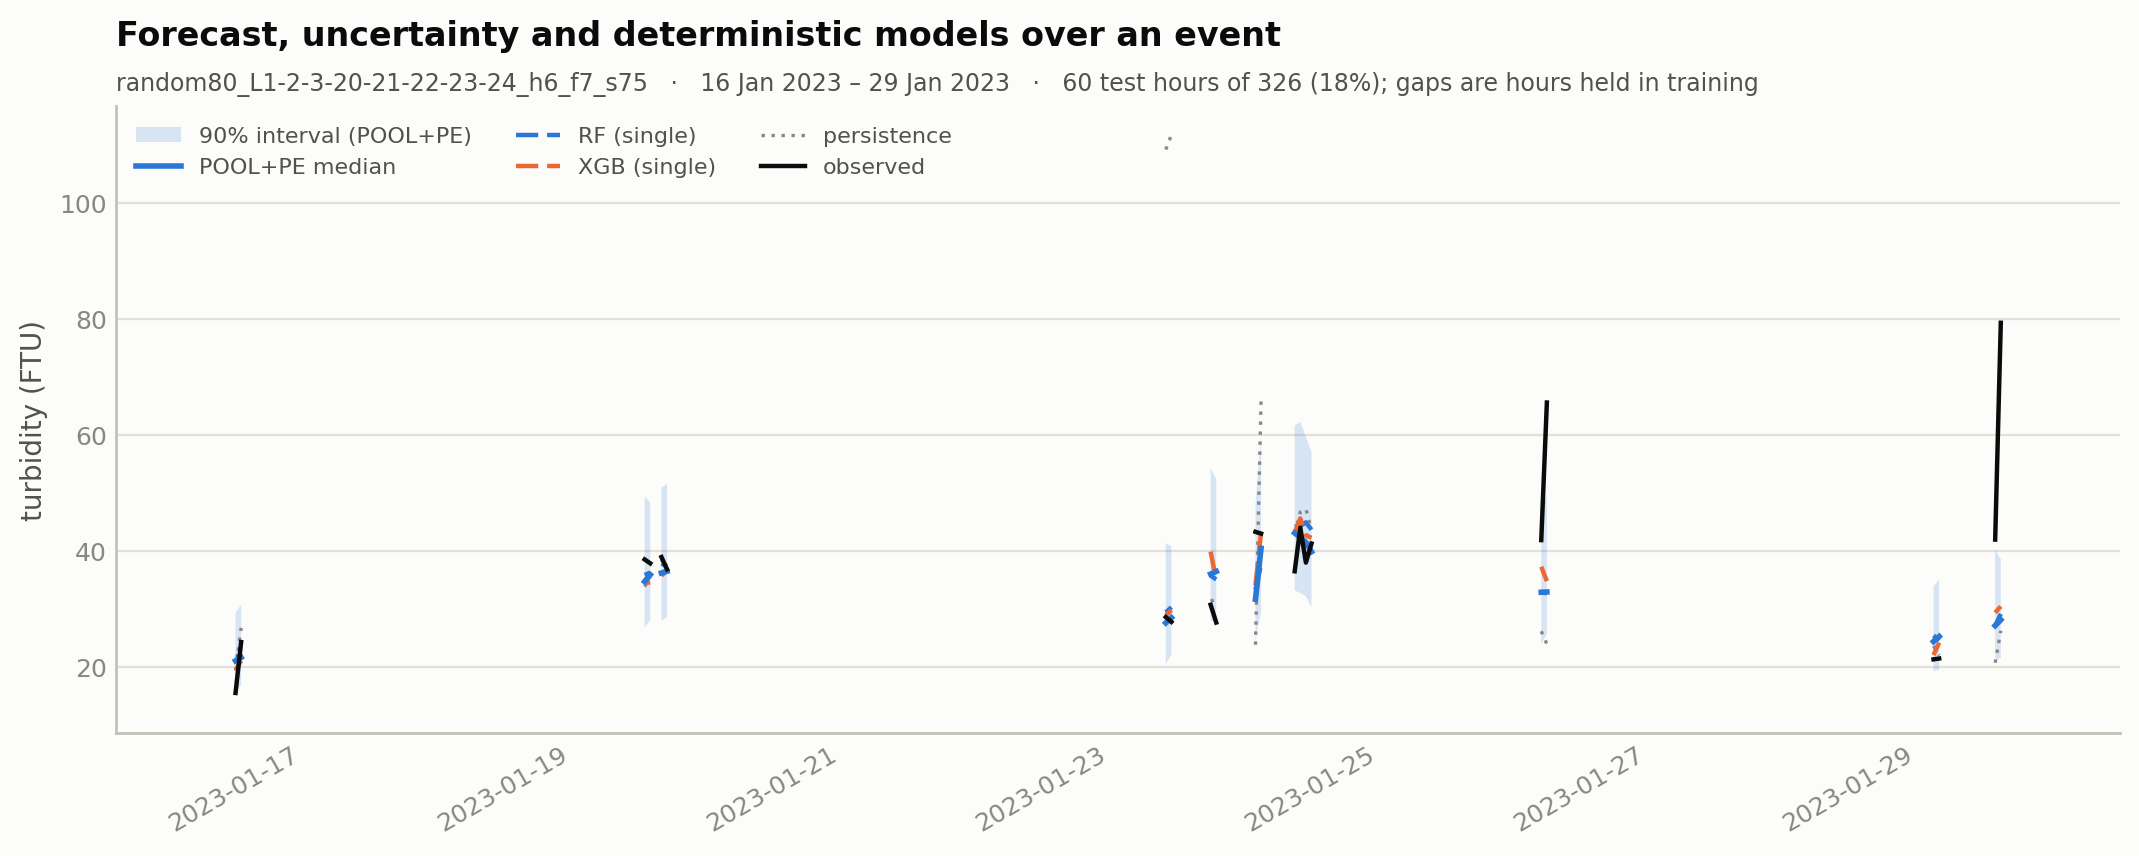

  -> trained_models_random80/uq/fig_uq_illustration_random80_L1-2-3-20-21-22-23-24_h6_f7_s75.png


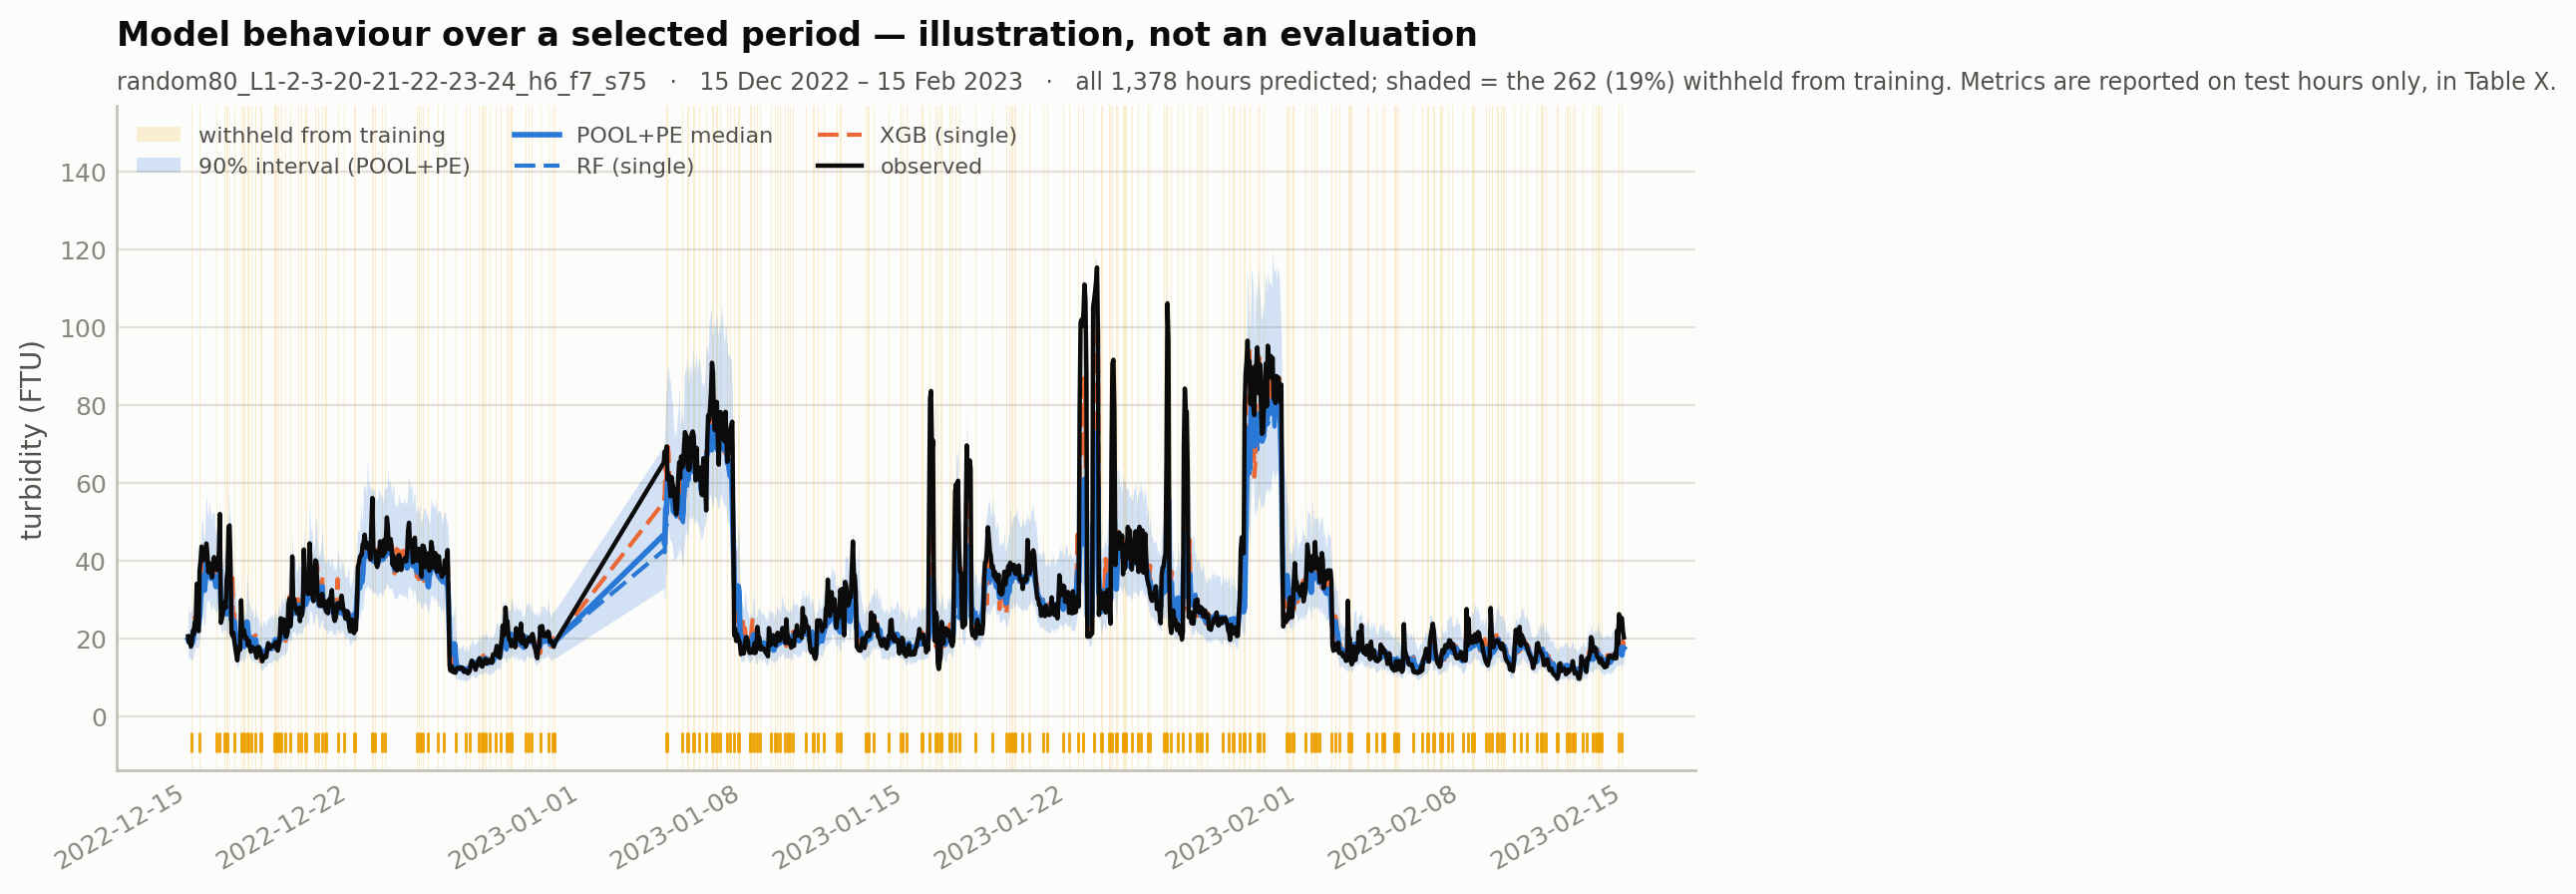

  -> trained_models_random80/uq/fig_uq_diagnostics_random80_L1-2-3-20-21-22-23-24_h6_f7_s75.png


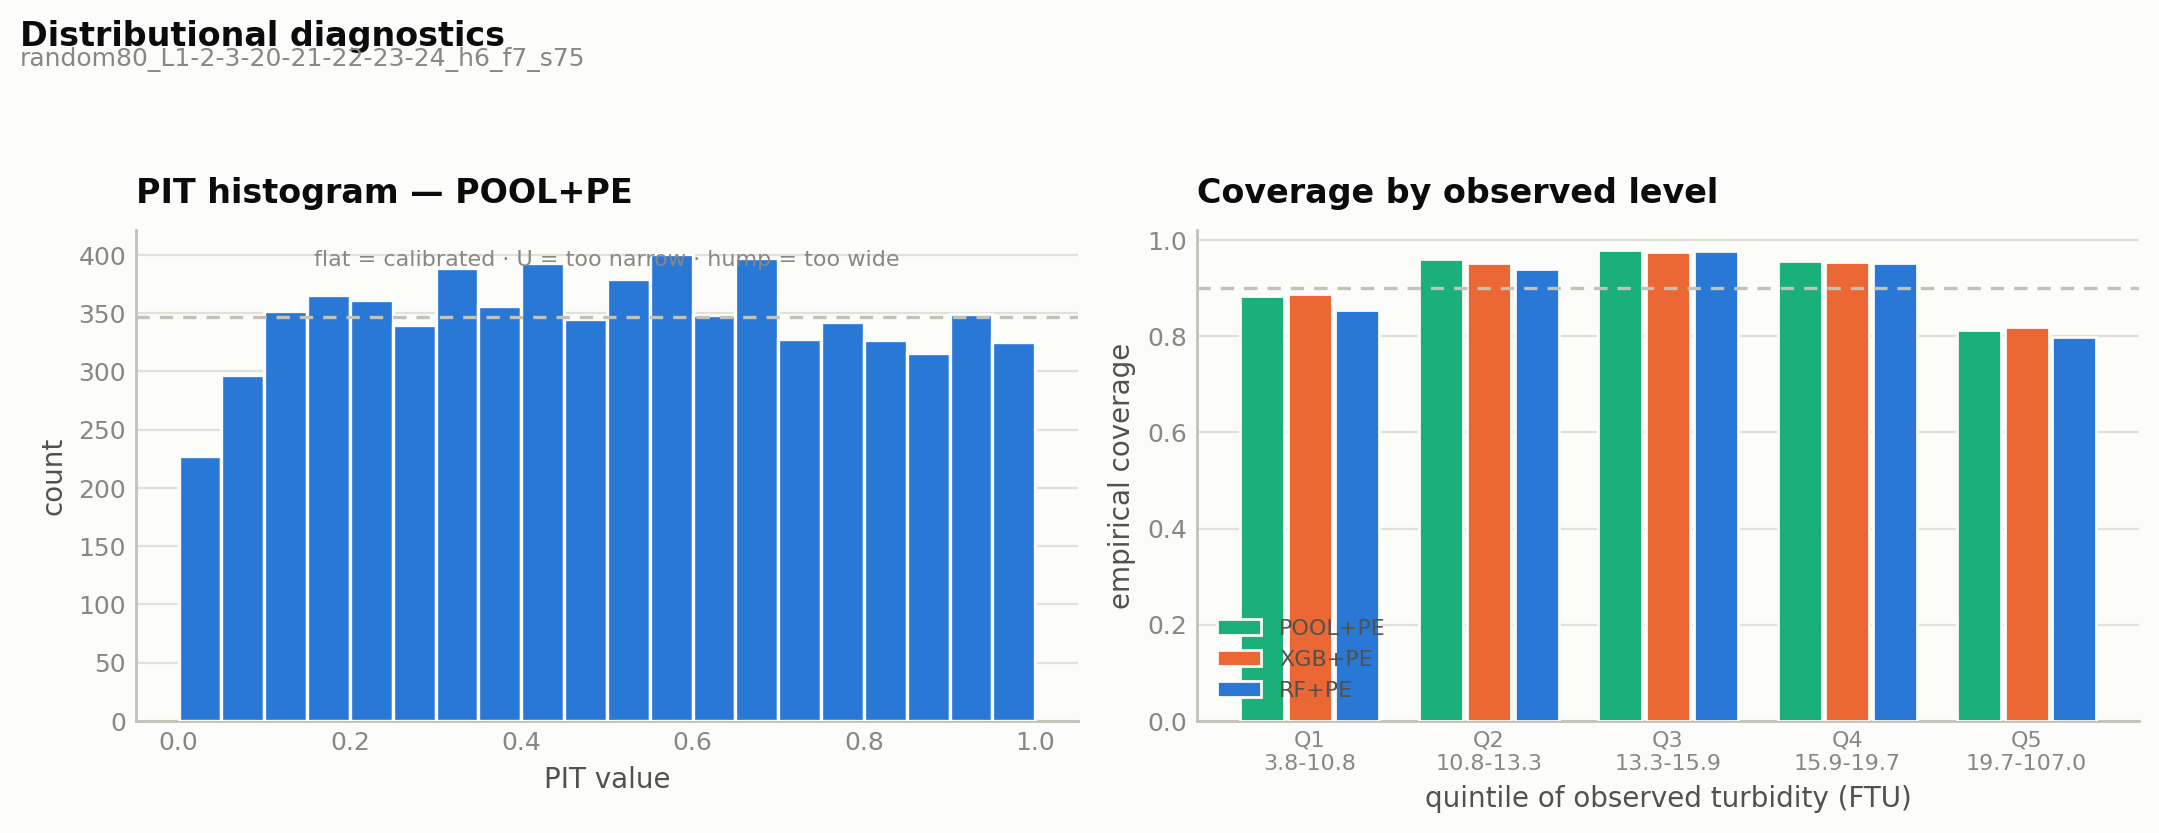


Done.


In [ ]:
import Bootstrap, bootstrap_horizons
#res = Bootstrap.run(horizon=6, split="random")
res = bootstrap_horizons.run(split="random")
res_6 = Bootstrap.run(horizon=6, split="random")
#res = multi_horizon_uq.run(horizons=(1, 2, 3), B=5)     # shorter trial # h = 1..6, B = 10

## **Classification model**

FEATURE_COLUMNS (7): ['sensor_turbidity', 'Hag_dis', 'sensor_temperature', 'Nieu_EC', 'Lob_turbidity', 'flow_direction', 'month']
tree lags: L1-2-3-20-21-22-23-24   horizons: (3, 6)
event: > P90 for >= 3 consecutive hours
split: 30-day blocks   modes: ('none', 'weight', 'adasyn')

HORIZON 3
Loaded 37,200 rows  (2019-12-01 00:00:00 -> 2024-02-27 23:00:00)
  valid: 35,178   invalid/gap-filled: 2,022

BLOCK split (30-day blocks, seed 42)
  52 blocks of 30 day(s); 11 assigned to test
  purged 468 boundary-crossing windows (1.35%) -- train and test share no raw hour
  train: 27,072 windows   (2020-01-02 02:00:00 -> 2024-02-07 23:00:00)
  test : 7,196 windows   (2020-04-30 02:00:00 -> 2024-02-26 20:00:00)   = 21.0%
  NOTE: no raw hour is shared, but test blocks are scattered through the record rather than following it. Seasonal climatology remains fully learnable. Still not a forward forecast.

  P90 of training targets = 23.94 FTU

EVENT LABELS
  full record: 2,655 event hours in 200 episod

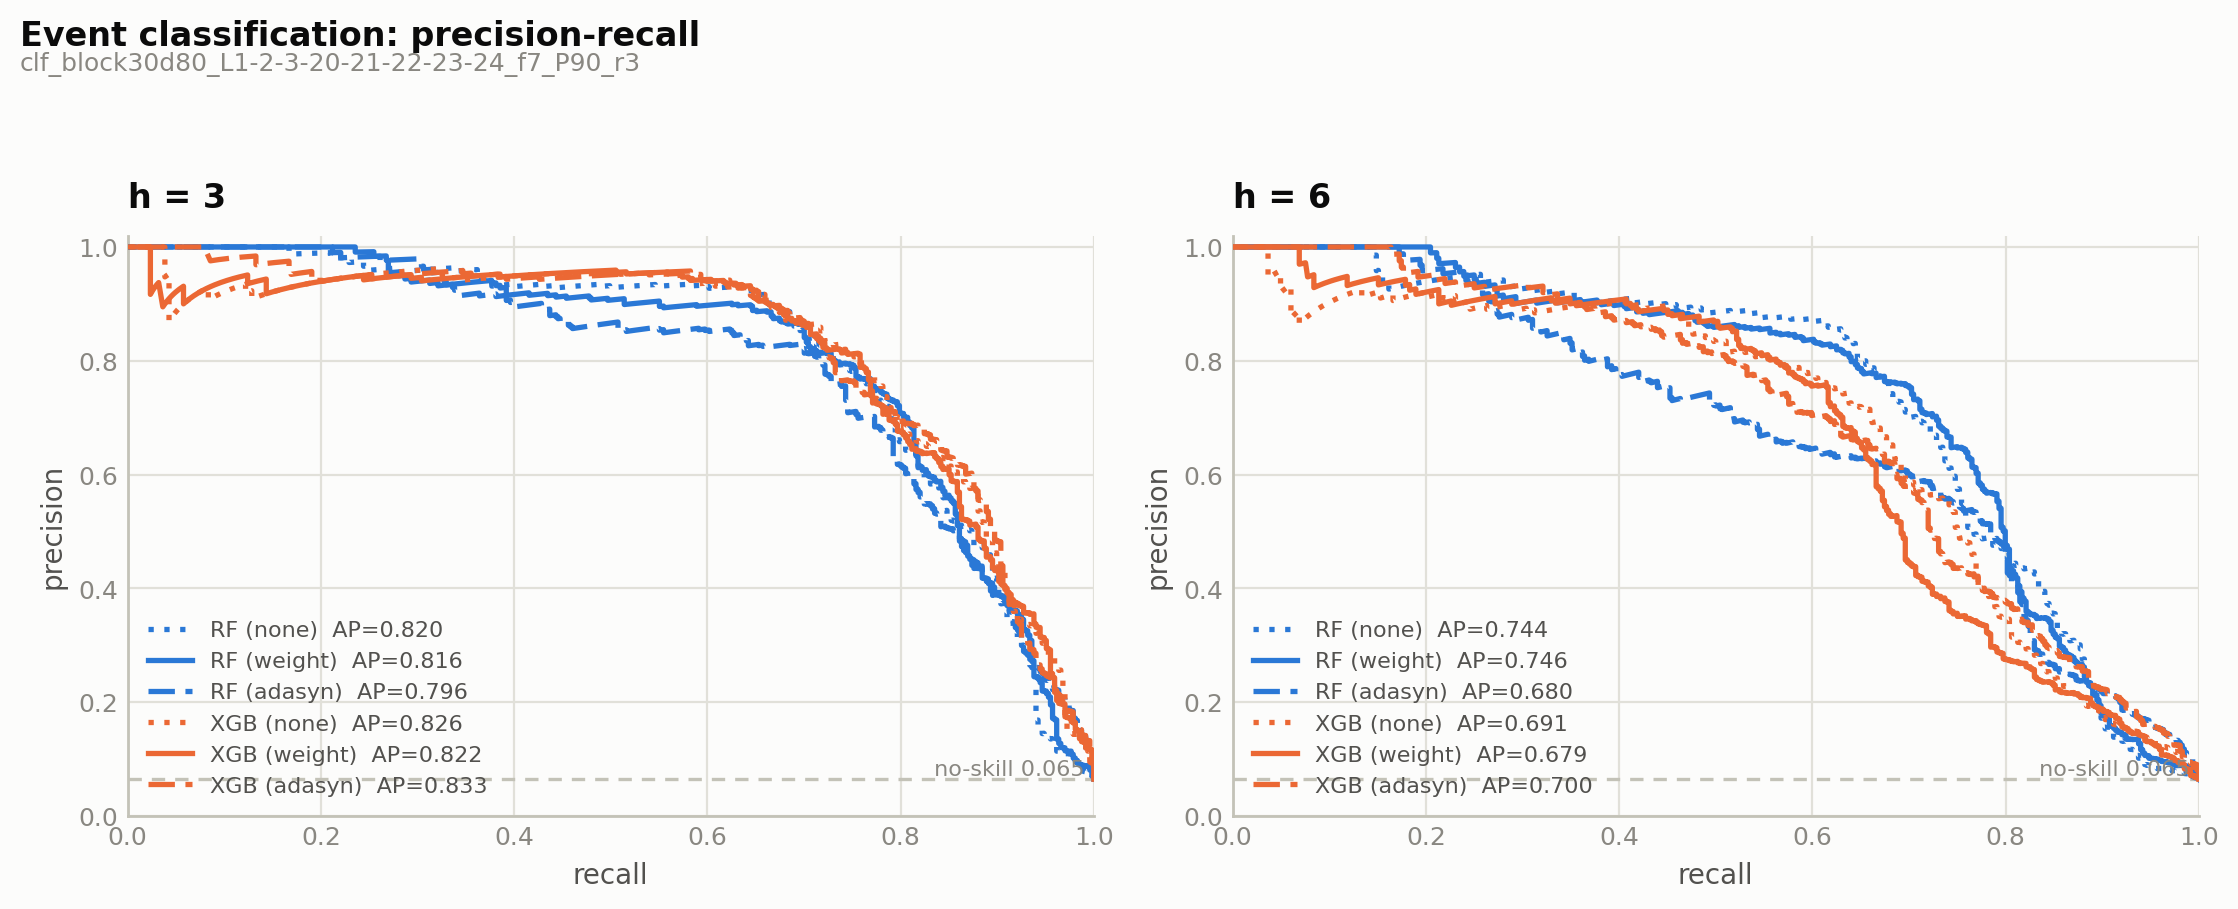


  h=3: best classifier XGB (weight), F1 0.780
      saved -> best_classifier_h3_xgb_weight_clf_block30d80_L1-2-3-20-21-22-23-24_f7_P90_r3.joblib (0.6 MB) + .json
       2022-12-15 to 2023-02-15: 743 of 1488 hours are in the test set (50%)

  h=6: best classifier RF (none), F1 0.708
      saved -> best_classifier_h6_rf_none_clf_block30d80_L1-2-3-20-21-22-23-24_f7_P90_r3.joblib (5.8 MB) + .json
       2022-12-15 to 2023-02-15: 740 of 1488 hours are in the test set (50%)
  -> trained_models_block30d80/events/fig_confusion_clf_block30d80_L1-2-3-20-21-22-23-24_f7_P90_r3.png


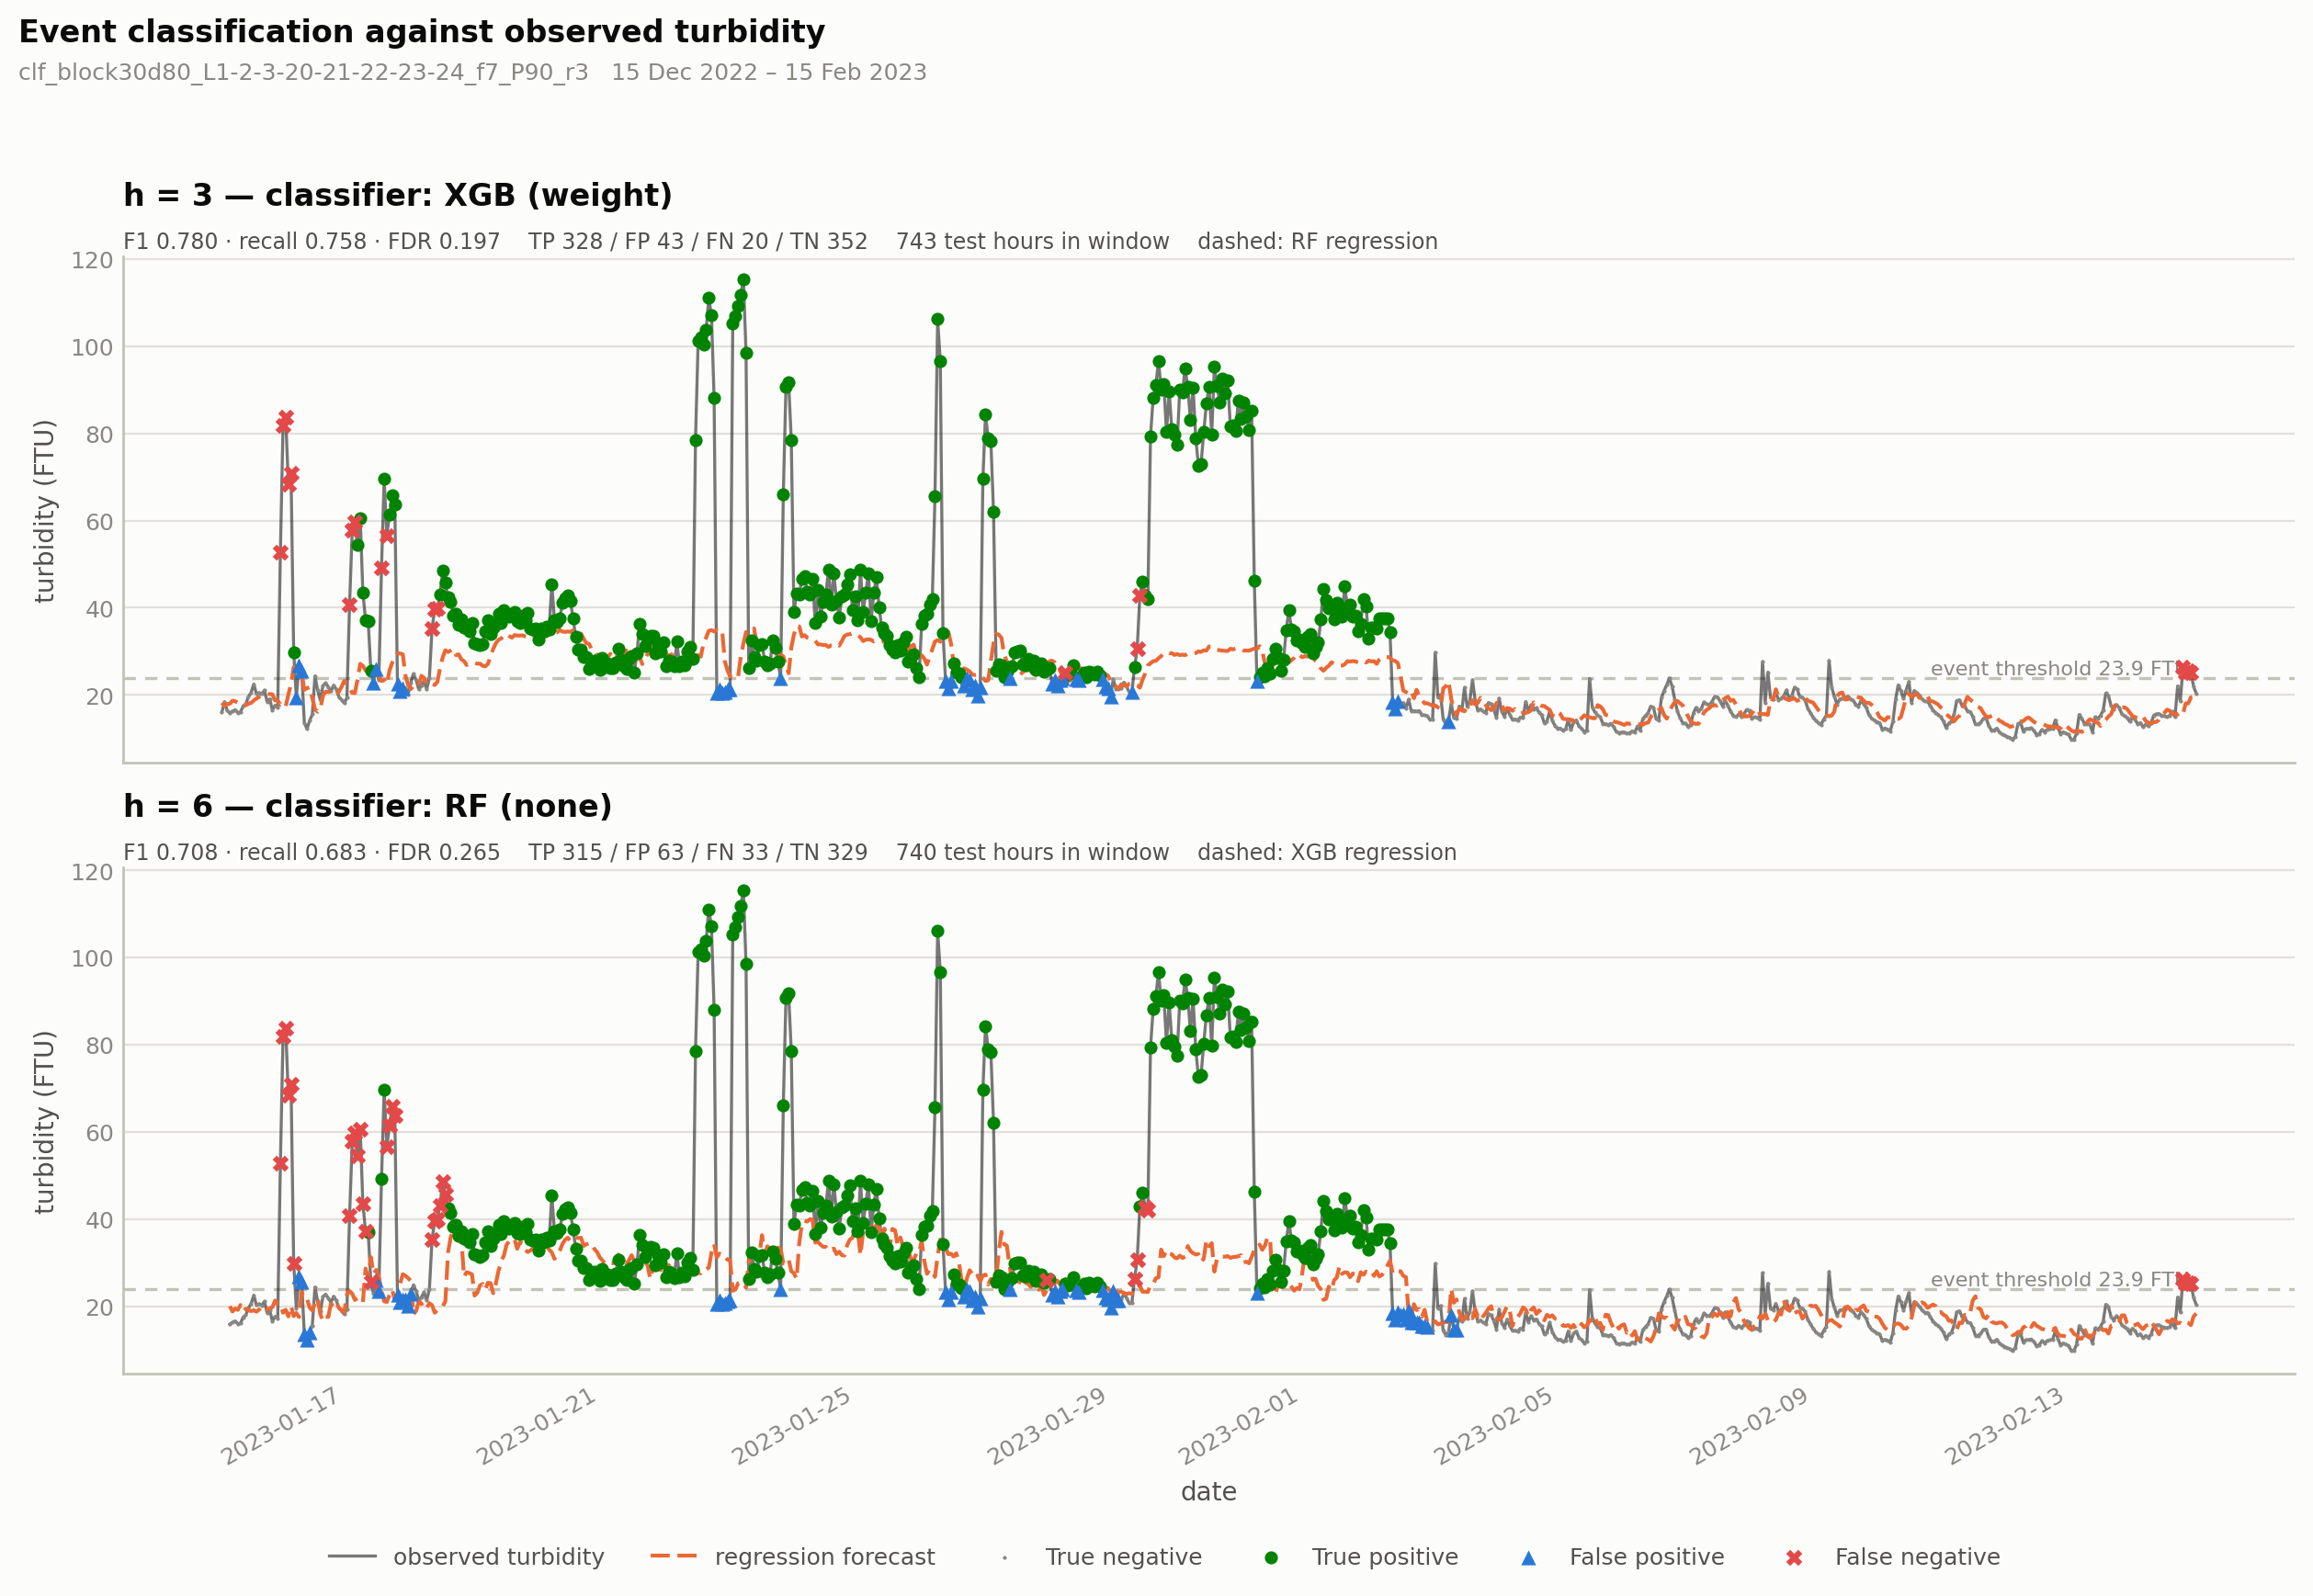


Done in 12.5 min -> trained_models_block30d80/events


In [ ]:
import Event_classification as E
res = E.run()